# **Прикладные задачи МО на графах. 29.10.2025**

Библиотека для работы с графовыми нейронными сетями  
[PyG (PyTorch Geometric)](https://github.com/rusty1s/pytorch_geometric).
PyTorch Geometric  - это расширение к [PyTorch](https://pytorch.org/).

In [ ]:
# Установка нужных пакетов
import os
import torch


!pip install -q torch-scatter -f https://data.pyg.org/whl/torch-2.4.0+cu121.html
!pip install -q torch-sparse -f https://data.pyg.org/whl/torch-2.4.0+cu121.html
!pip install -q torch-geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 61.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 35.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 17.8 MB/s eta 0:00:00


In [ ]:
# Для лучшей визуализации
%matplotlib inline
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE


def visualize_graph(G, color):
    plt.figure(figsize=(7,7))
    plt.xticks([])
    plt.yticks([])
    nx.draw_networkx(G, pos=nx.spring_layout(G, seed=42), with_labels=False,
                     node_color=color, cmap="Set2")
    plt.show()


def visualize_embedding(h, color, epoch=None, loss=None):
    plt.figure(figsize=(7,7))
    plt.xticks([])
    plt.yticks([])
    h = h.detach().cpu().numpy()
    plt.scatter(h[:, 0], h[:, 1], s=140, c=color, cmap="Set2")
    if epoch is not None and loss is not None:
        plt.xlabel(f'Epoch: {epoch}, Loss: {loss.item():.4f}', fontsize=16)
    plt.show()

def visualize(h, color):
    z = TSNE(n_components=2).fit_transform(h.detach().cpu().numpy())

    plt.figure(figsize=(10,10))
    plt.xticks([])
    plt.yticks([])

    plt.scatter(z[:, 0], z[:, 1], s=70, c=color, cmap="Set2")
    plt.show()

# Введение

**Графовые нейронные сети (Graph Neural Networks (GNNs))** - обобщение концепции глубокого обучения для работы с данными, которые не представимы в виде регулярных объектов (текст, картинки).

Основная идея: передача сообщений (neural message passing scheme), при которой признаки вершин $\mathbf{x}_v^{(\ell)}$ итеративно  обновляются на основе признаков соседей вершины $\mathcal{N}(v)$ в графе $\mathcal{G} = (\mathcal{V}, \mathcal{E})$:

$$
\mathbf{x}_v^{(\ell + 1)} = f^{(\ell + 1)}_{\theta} \left( \mathbf{x}_v^{(\ell)}, \left\{ \mathbf{x}_w^{(\ell)} : w \in \mathcal{N}(v) \right\} \right).
$$


Для примера рассмотрим [Zachary's karate club network](https://en.wikipedia.org/wiki/Zachary%27s_karate_club).


Датасеты в PyG: [`torch_geometric.datasets`](https://pytorch-geometric.readthedocs.io/en/latest/modules/datasets.html#torch_geometric.datasets) .

In [ ]:
from torch_geometric.datasets import KarateClub

dataset = KarateClub()
print(f'Dataset: {dataset}:')
print('======================')
print(f'Number of graphs: {len(dataset)}')
print(f'Number of features: {dataset.num_features}')
print(f'Number of classes: {dataset.num_classes}')

/usr/local/lib/python3.12/dist-packages/torch_geometric/__init__.py:4: UserWarning: An issue occurred while importing 'torch-scatter'. Disabling its usage. Stacktrace: /usr/local/lib/python3.12/dist-packages/torch_scatter/_version_cuda.so: undefined symbol: _ZN5torch3jit17parseSchemaOrNameERKSsb
  import torch_geometric.typing
/usr/local/lib/python3.12/dist-packages/torch_geometric/__init__.py:4: UserWarning: An issue occurred while importing 'torch-sparse'. Disabling its usage. Stacktrace: /usr/local/lib/python3.12/dist-packages/torch_sparse/_version_cuda.so: undefined symbol: _ZN5torch3jit17parseSchemaOrNameERKSsb
  import torch_geometric.typing


Dataset: KarateClub():
Number of graphs: 1
Number of features: 34
Number of classes: 4


Свойства датасета: граф на 34 вершинах, каждой вершине сопоставлен 34-размерный вектор признаков, Вершины разделены на 4 класса (сообщества).

[`KarateClub`](https://pytorch-geometric.readthedocs.io/en/latest/modules/datasets.html#torch_geometric.datasets.KarateClub)

In [ ]:
data = dataset[0]  # Выбираем датасет (граф)

print(data)
print('==============================================================')

# Немного описательной статистики
print(f'Number of nodes: {data.num_nodes}')
print(f'Number of edges: {data.num_edges}')
print(f'Average node degree: {data.num_edges / data.num_nodes:.2f}')
print(f'Number of training nodes: {data.train_mask.sum()}')
print(f'Training node label rate: {int(data.train_mask.sum()) / data.num_nodes:.2f}')
print(f'Has isolated nodes: {data.has_isolated_nodes()}')
print(f'Has self-loops: {data.has_self_loops()}')
print(f'Is undirected: {data.is_undirected()}')

Data(x=[34, 34], edge_index=[2, 156], y=[34], train_mask=[34])
Number of nodes: 34
Number of edges: 156
Average node degree: 4.59
Number of training nodes: 4
Training node label rate: 0.12
Has isolated nodes: False
Has self-loops: False
Is undirected: True


Граф в PyTorch Geometric представляется объектом типа [`Data`](https://pytorch-geometric.readthedocs.io/en/latest/modules/data.html#torch_geometric.data.Data), содержащим информацию о графе.

```
Data(edge_index=[2, 156], x=[34, 34], y=[34], train_mask=[34])
```

(1)  `edge_index`  - информация о связях в графе (кортеж из вершины-начала и вершины-конца для каждого ребра)

(2) Признаковое описание вершин (node features) `x` (каждой из 34 вершин соответствует 34-размерный вектор)

(3) Метки/классы для вершин  (node labels)  `y`.

(4)  `train_mask` описывает, для каких вершин известен класс, к которому она принадлежит (по одной вершине из каждого класса).

Рассмотрим  `edge_index`:

In [ ]:
from IPython.display import Javascript  # Restrict height of output cell.
display(Javascript('''google.colab.output.setIframeHeight(0, true, {maxHeight: 300})'''))

edge_index = data.edge_index
print(edge_index.t())

<IPython.core.display.Javascript object>

tensor([[ 0,  1],
        [ 0,  2],
        [ 0,  3],
        [ 0,  4],
        [ 0,  5],
        [ 0,  6],
        [ 0,  7],
        [ 0,  8],
        [ 0, 10],
        [ 0, 11],
        [ 0, 12],
        [ 0, 13],
        [ 0, 17],
        [ 0, 19],
        [ 0, 21],
        [ 0, 31],
        [ 1,  0],
        [ 1,  2],
        [ 1,  3],
        [ 1,  7],
        [ 1, 13],
        [ 1, 17],
        [ 1, 19],
        [ 1, 21],
        [ 1, 30],
        [ 2,  0],
        [ 2,  1],
        [ 2,  3],
        [ 2,  7],
        [ 2,  8],
        [ 2,  9],
        [ 2, 13],
        [ 2, 27],
        [ 2, 28],
        [ 2, 32],
        [ 3,  0],
        [ 3,  1],
        [ 3,  2],
        [ 3,  7],
        [ 3, 12],
        [ 3, 13],
        [ 4,  0],
        [ 4,  6],
        [ 4, 10],
        [ 5,  0],
        [ 5,  6],
        [ 5, 10],
        [ 5, 16],
        [ 6,  0],
        [ 6,  4],
        [ 6,  5],
        [ 6, 16],
        [ 7,  0],
        [ 7,  1],
        [ 7,  2],
        [ 

PyG хранит не всю матрицу смежности $\mathbf{A} \in \{ 0, 1 \}^{|\mathcal{V}| \times |\mathcal{V}|}$, а только координаты ненулевых элементов (COO format (coordinate format)).

Для PyG неориентированные графы  - это ориентированные графы, в которых для каждого ребра существует обратное.

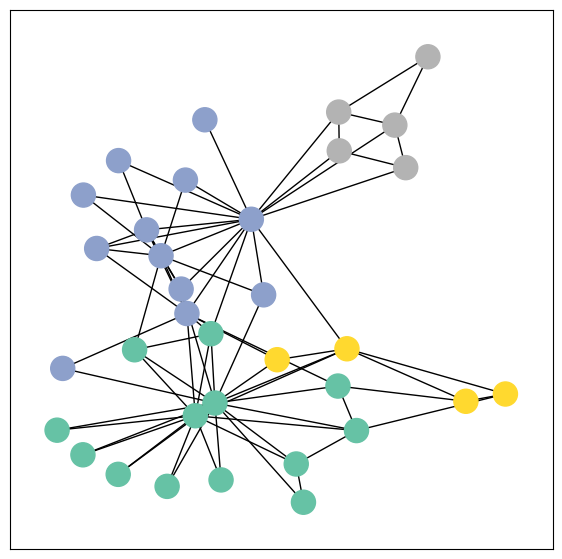

In [ ]:
from torch_geometric.utils import to_networkx

G = to_networkx(data, to_undirected=True)
visualize_graph(G, color=data.y)

## Graph Neural Networks

По ([Kipf et al. (2017)](https://arxiv.org/abs/1609.02907)) построим GNN из GCN слоёв:


$$
\mathbf{x}_v^{(\ell + 1)} = \mathbf{W}^{(\ell + 1)} \sum_{w \in \mathcal{N}(v) \, \cup \, \{ v \}} \frac{1}{c_{w,v}} \cdot \mathbf{x}_w^{(\ell)}
$$

$\mathbf{W}^{(\ell + 1)}$  - матрица весов размера `[num_output_features, num_input_features]`
$c_{w,v}$ фиксированные коэффициенты нормирования для каждого ребра.

В PyG реализован слой [`GCNConv`](https://pytorch-geometric.readthedocs.io/en/latest/modules/nn.html#torch_geometric.nn.conv.GCNConv), использующий признаки узлов (node feature representation) `x` and сведения о связи между вершинами `edge_index`.

Архитектура сети определяется в классе `torch.nn.Module`:

In [ ]:
import torch
from torch.nn import Linear
from torch_geometric.nn import GCNConv


class GCN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        torch.manual_seed(1234)
        self.conv1 = GCNConv(dataset.num_features, 4)
        self.conv2 = GCNConv(4, 4)
        self.conv3 = GCNConv(4, 2)
        self.classifier = Linear(2, dataset.num_classes)

    def forward(self, x, edge_index):
        h = self.conv1(x, edge_index)
        h = h.tanh()
        h = self.conv2(h, edge_index)
        h = h.tanh()
        h = self.conv3(h, edge_index)
        h = h.tanh()  # Финальные признаки

        # Линейный классификатор
        out = self.classifier(h)

        return out, h

model = GCN()
print(model)

GCN(
  (conv1): GCNConv(34, 4)
  (conv2): GCNConv(4, 4)
  (conv3): GCNConv(4, 2)
  (classifier): Linear(in_features=2, out_features=4, bias=True)
)


Проход вперед (forward pass).

Сеть из 3-х сверточных слоёв, т.е. учитываем информацию от на расстоянии 3, одновременно уменьшая размерность вектора признаков до  $2$: $34 \rightarrow 4 \rightarrow 4 \rightarrow 2$. В качестве функции активации выбран   [tanh](https://pytorch.org/docs/stable/generated/torch.nn.Tanh.html?highlight=tanh#torch.nn.Tanh).

Для классификации узлов используем ([`torch.nn.Linear`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html?highlight=linear#torch.nn.Linear)).

### Эмбеддинги  вершин  Karate Club Network

Embedding shape: [34, 2]


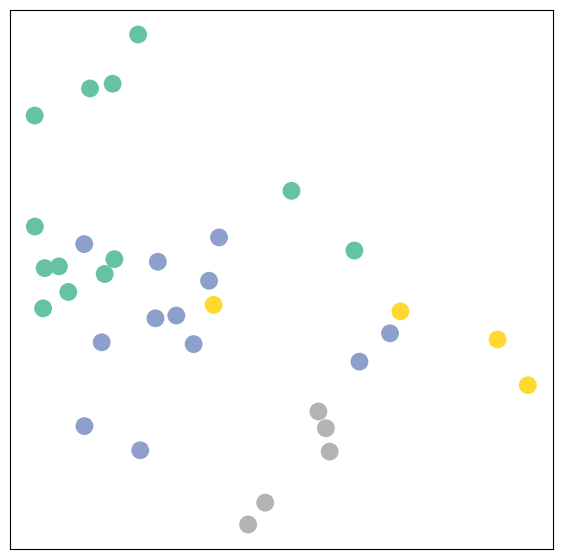

In [ ]:
model = GCN()

_, h = model(data.x, data.edge_index)
print(f'Embedding shape: {list(h.shape)}')

visualize_embedding(h, color=data.y)

In [ ]:
data.train_mask

tensor([ True, False, False, False,  True, False, False, False,  True, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False, False,  True, False, False, False, False, False,
        False, False, False, False])

In [ ]:
data.y

tensor([1, 1, 1, 1, 3, 3, 3, 1, 0, 1, 3, 1, 1, 1, 0, 0, 3, 1, 0, 1, 0, 1, 0, 0,
        2, 2, 0, 0, 2, 0, 0, 2, 0, 0])

### Обучение

Обучение на частично размеченных данных (semi-supervised or transductive learning procedure): возьмем по одному узлу из каждого класса.


Функция потерь Loss[`CrossEntropyLoss`](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)
Для вычисления стохастического градиентного спуска stochastic gradient optimizer  [`Adam`](https://pytorch.org/docs/stable/optim.html?highlight=adam#torch.optim.Adam)).

[Руководство по обучению сетей в PyTorch](https://pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html#define-a-loss-function-and-optimizer).

Для semi-supervised learning:
```
loss = criterion(out[data.train_mask], data.y[data.train_mask])
```

Эмбеддинги рассчитываются для всех узлов, но функция потерь считается только по узлам из тренировочной выборки (узлов, для которых известны классы).


<IPython.core.display.Javascript object>

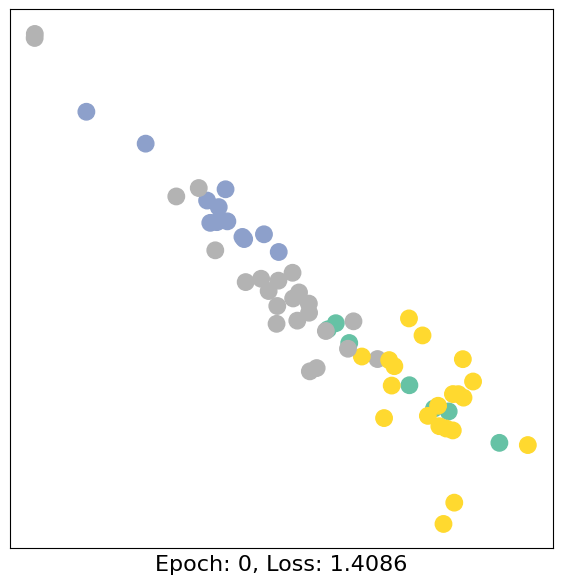

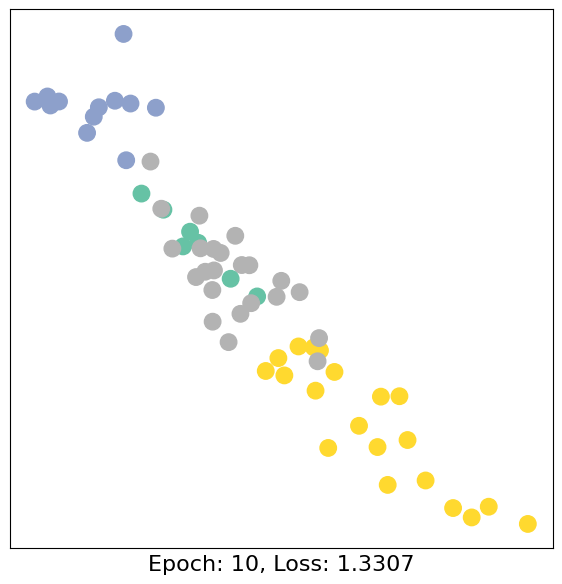

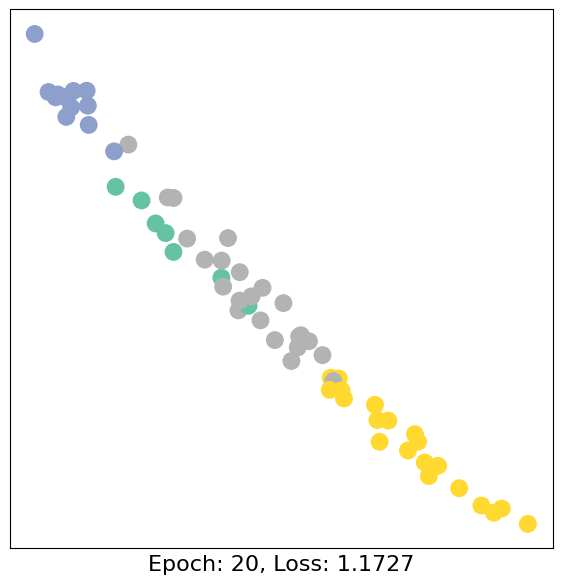

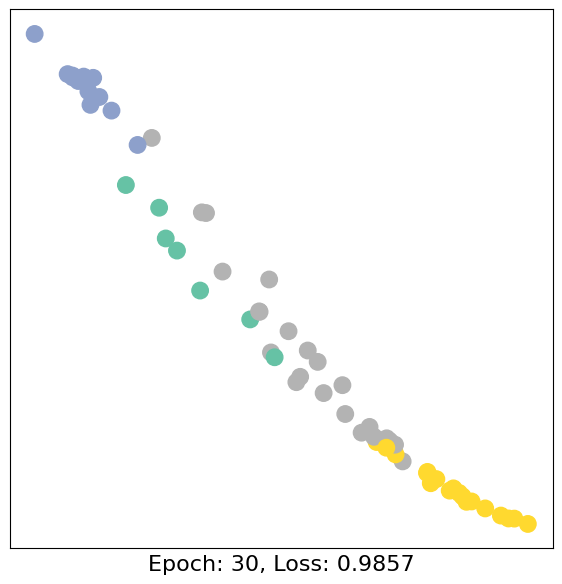

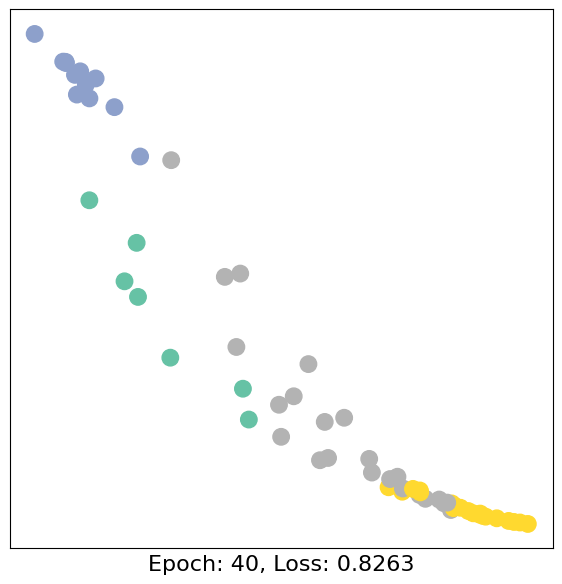

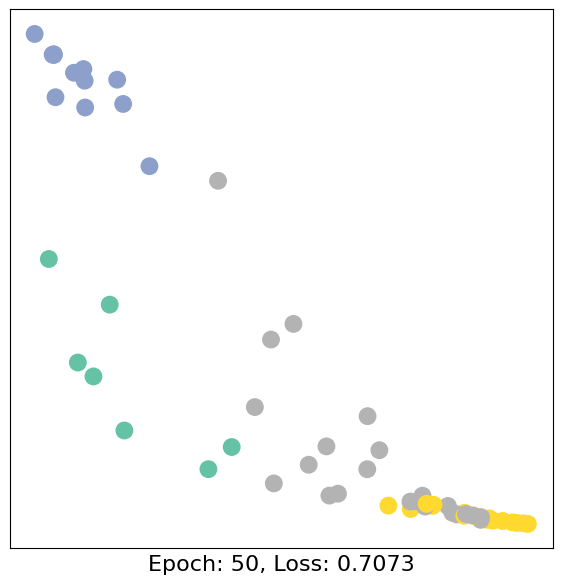

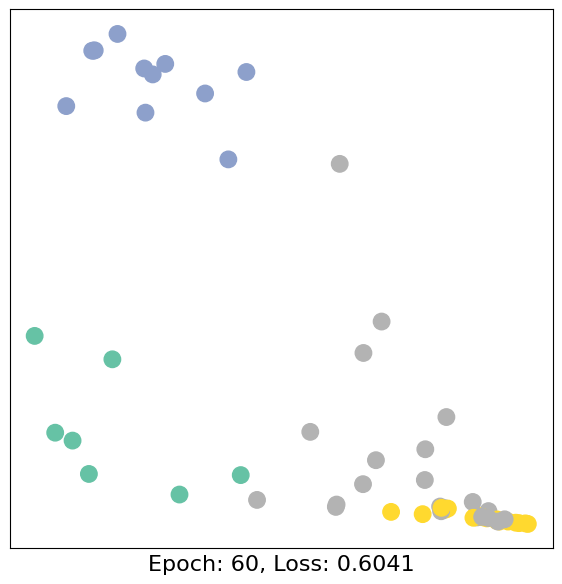

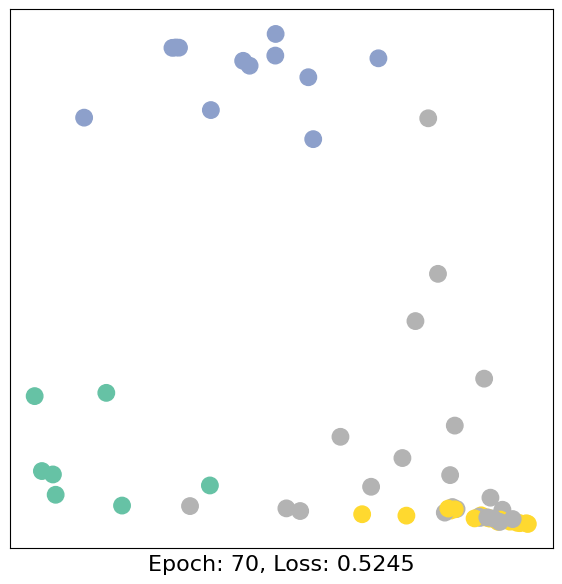

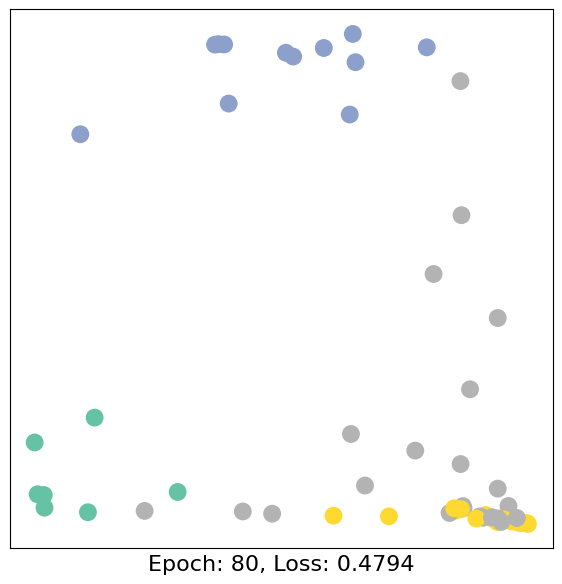

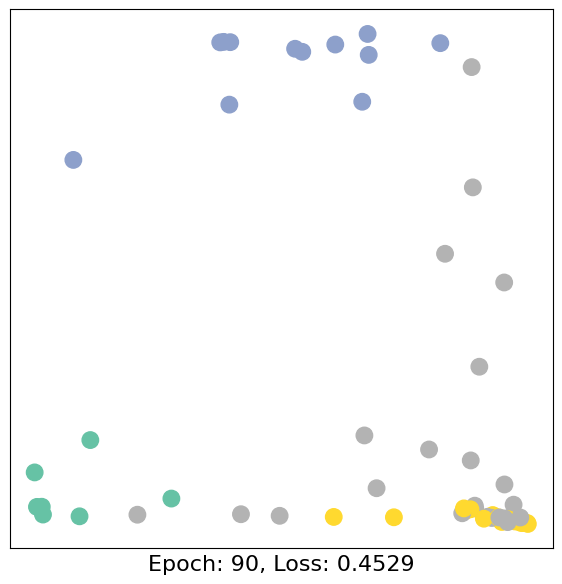

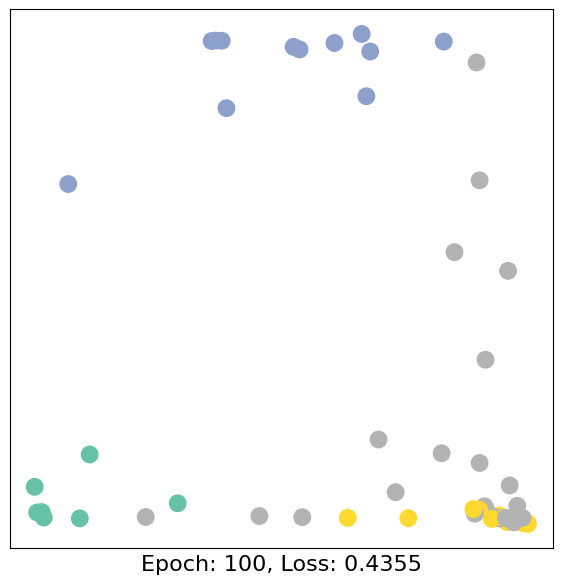

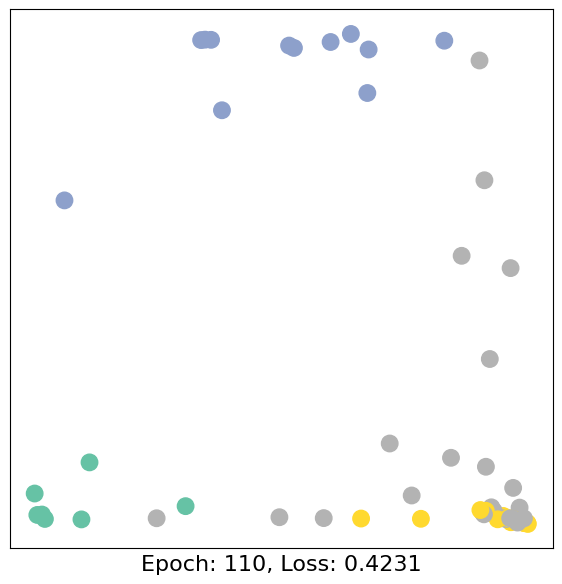

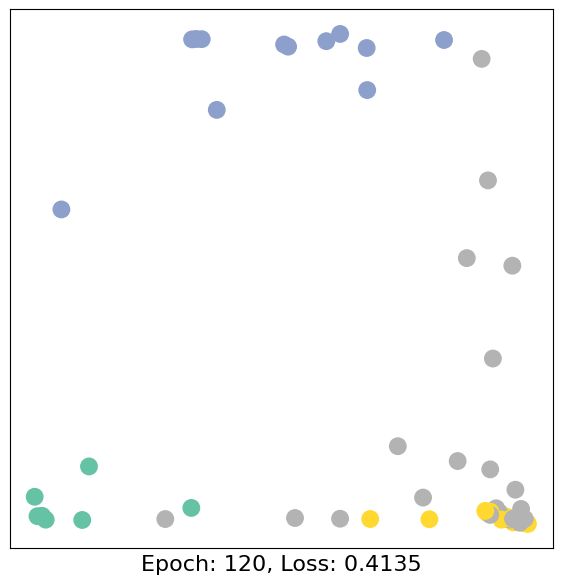

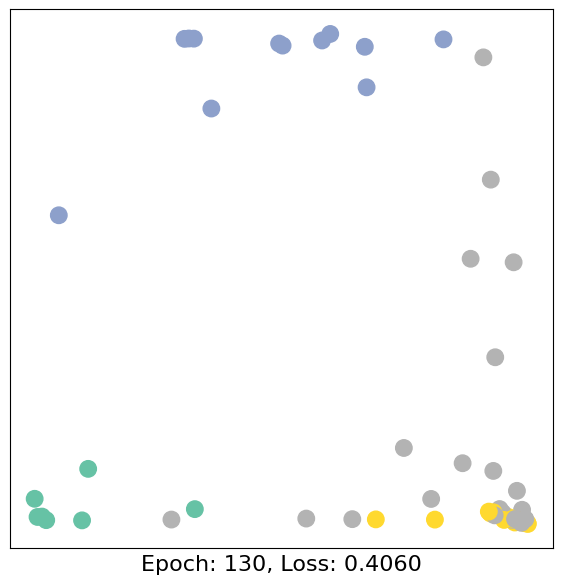

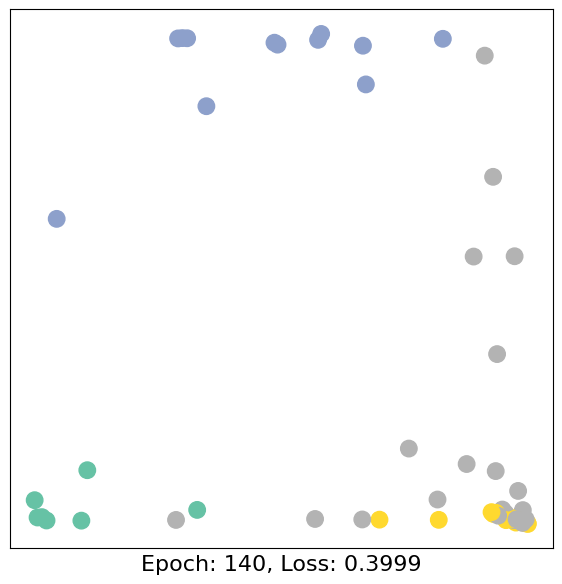

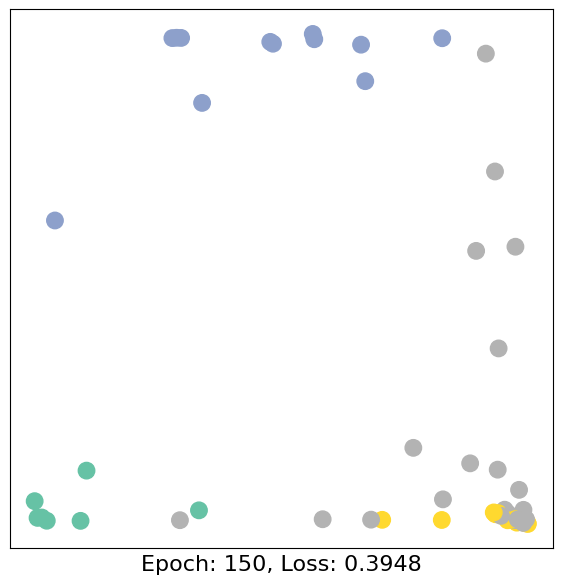

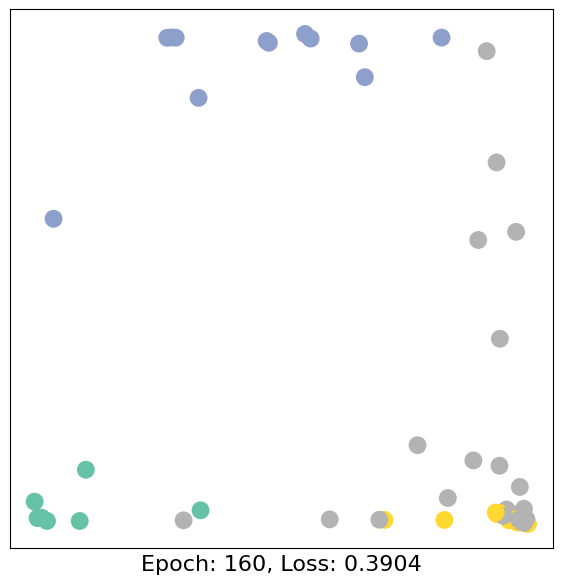

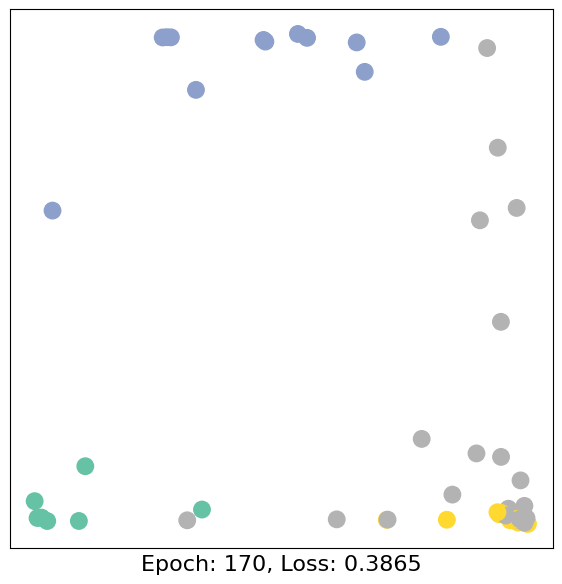

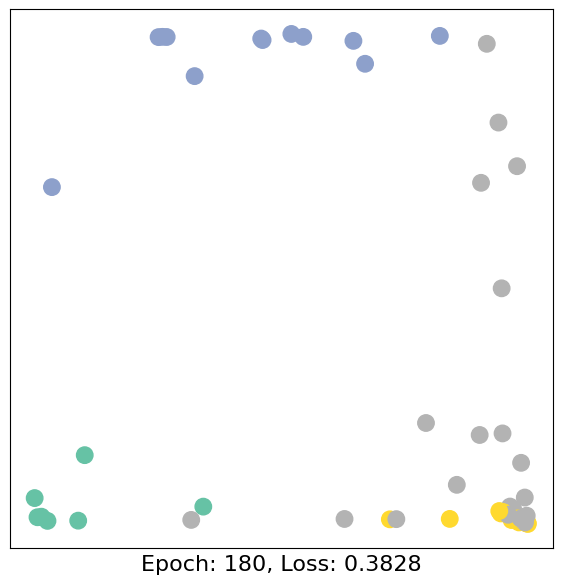

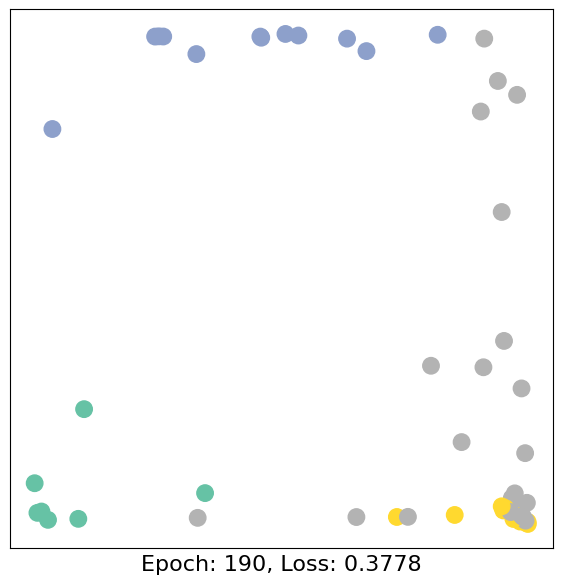

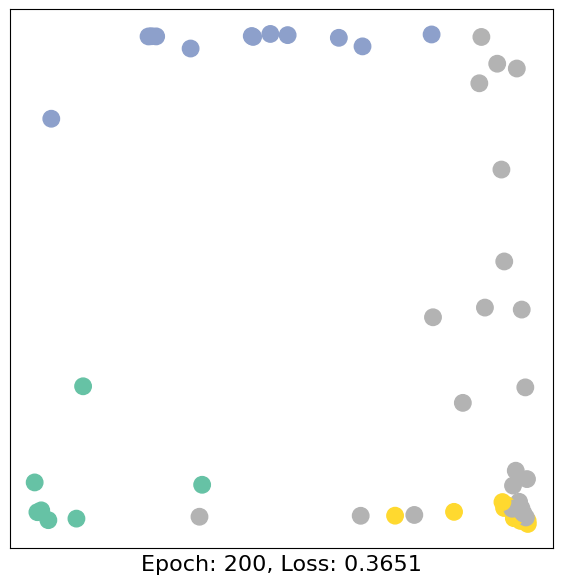

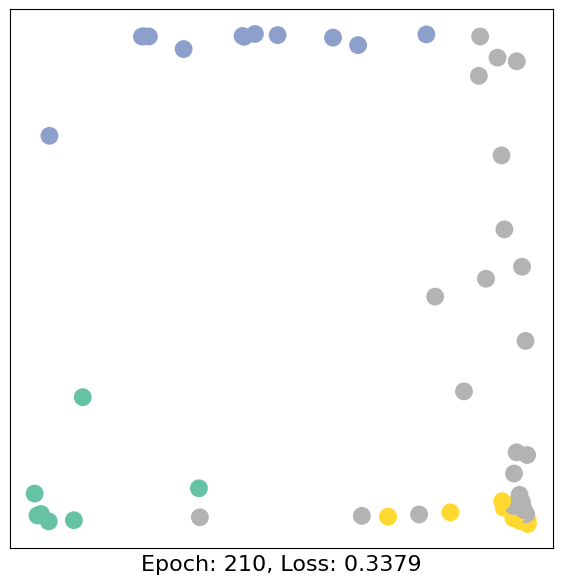

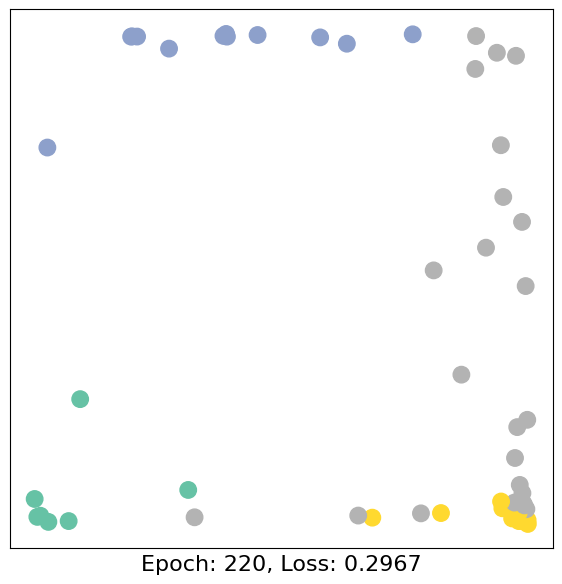

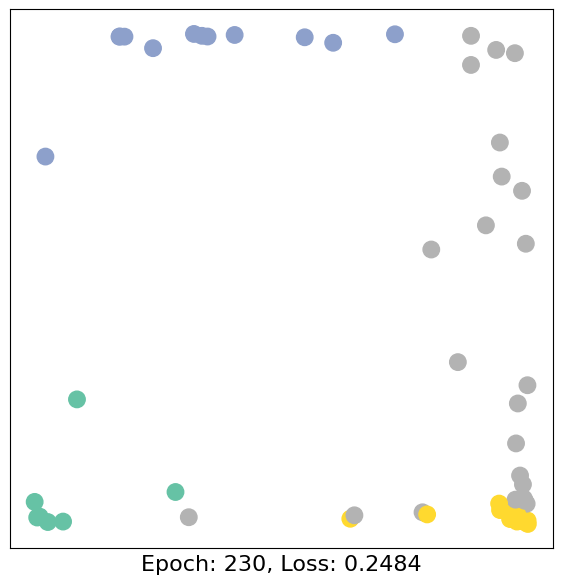

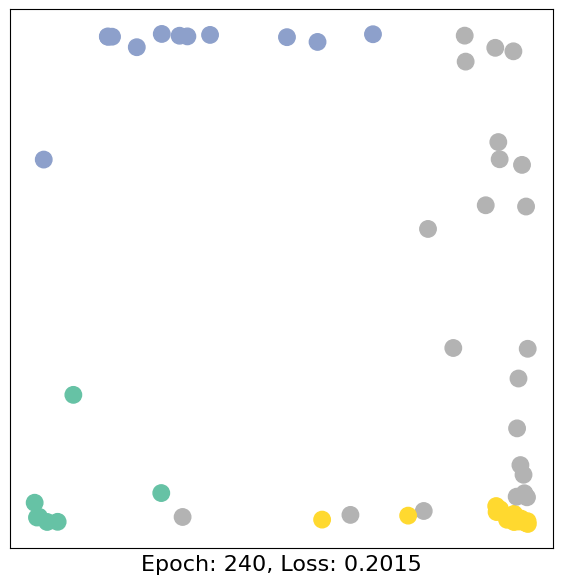

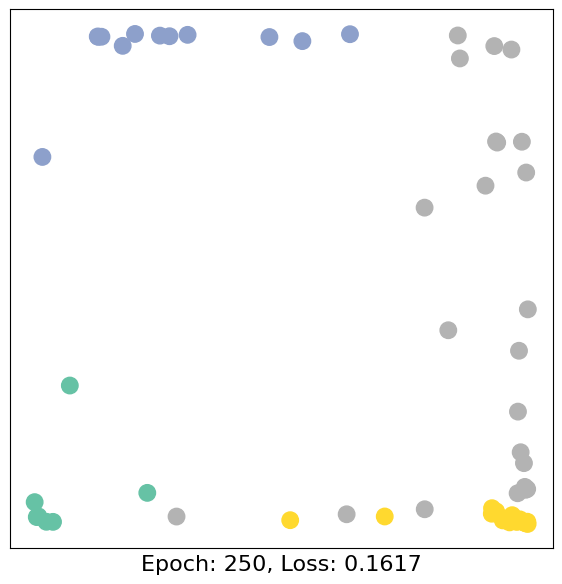

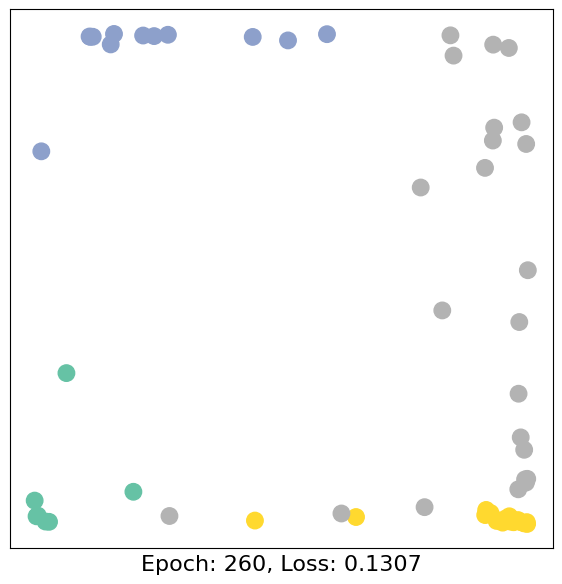

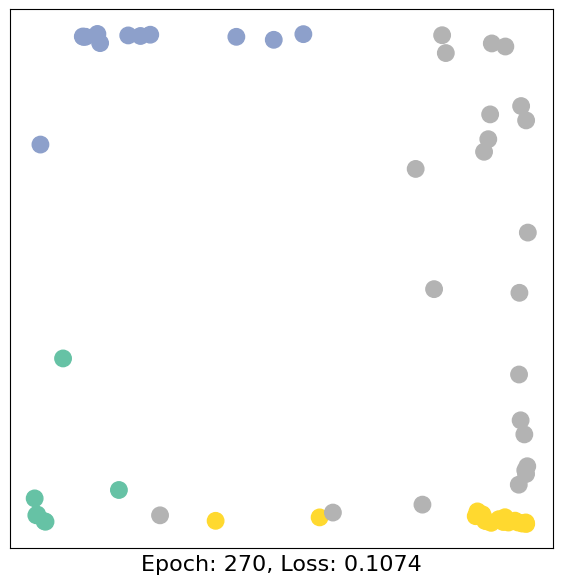

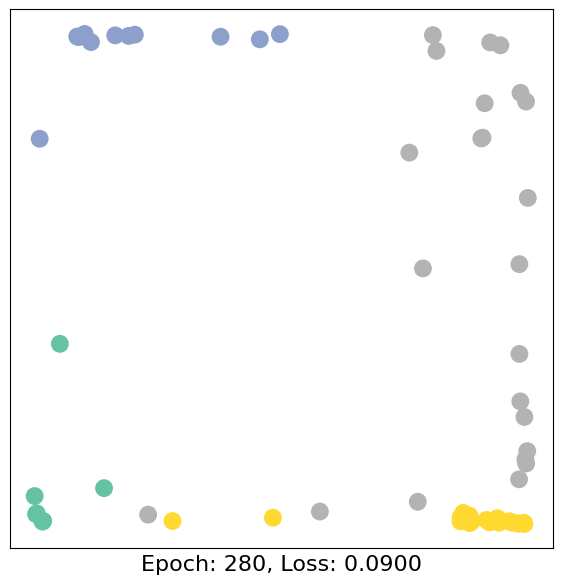

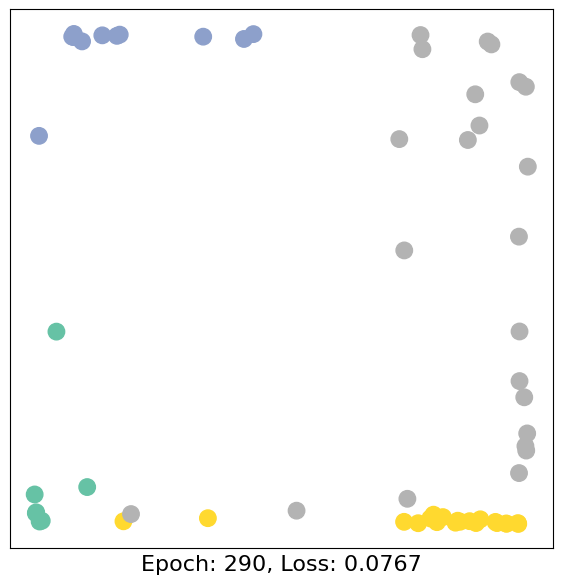

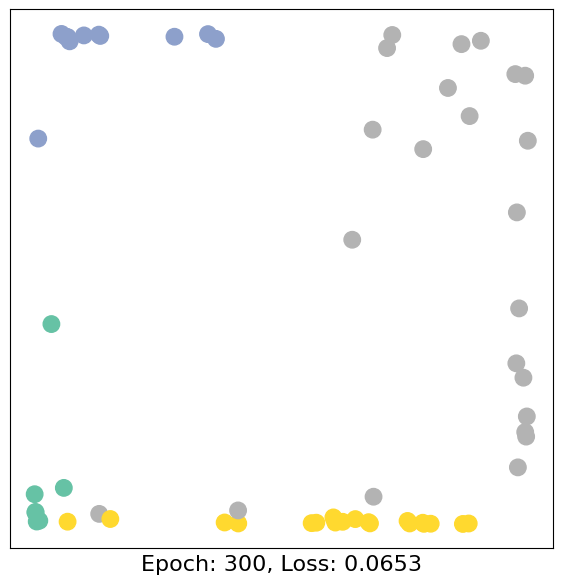

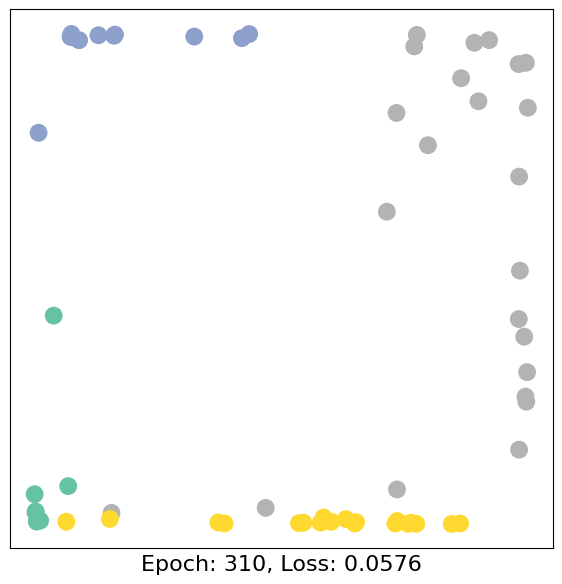

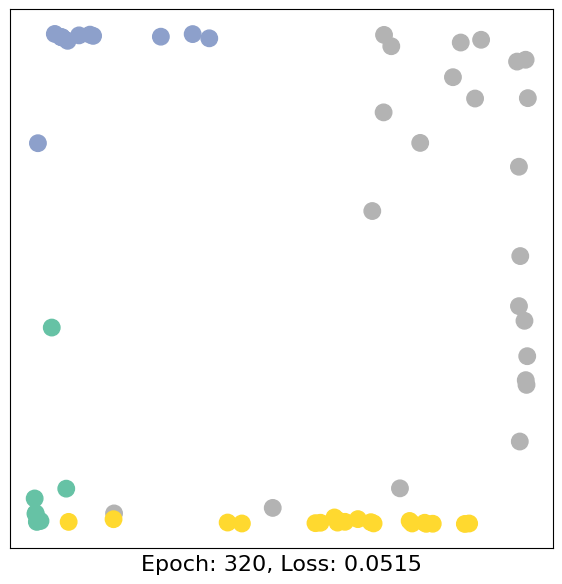

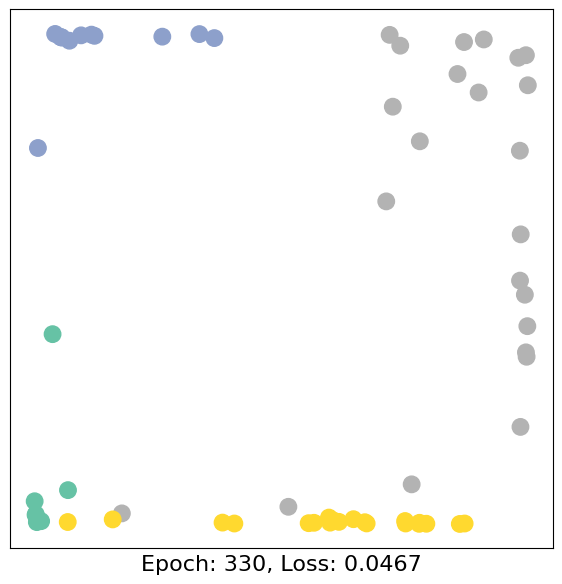

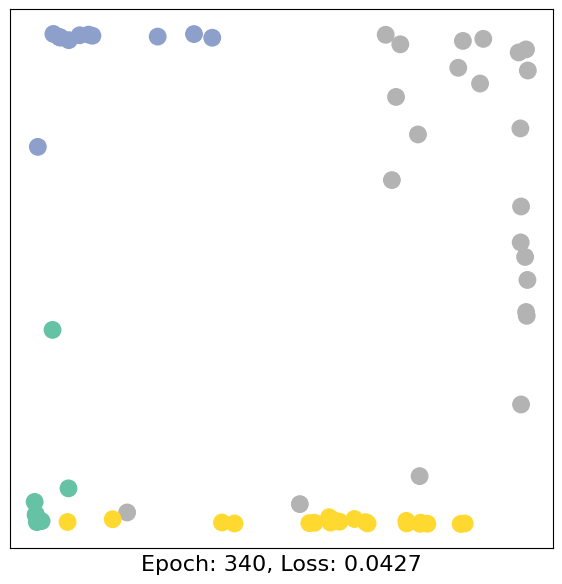

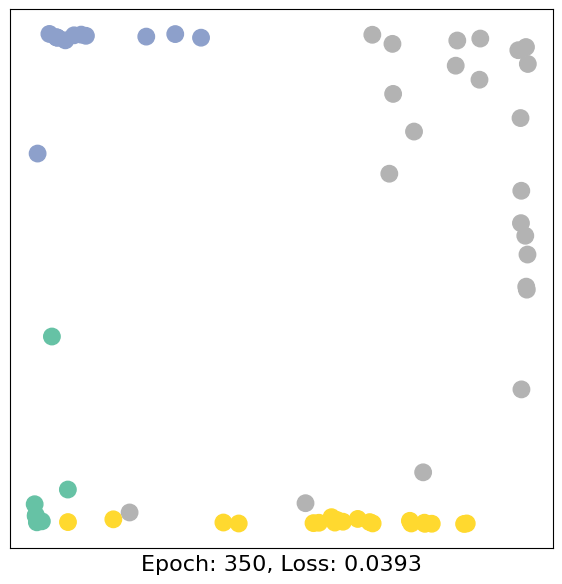

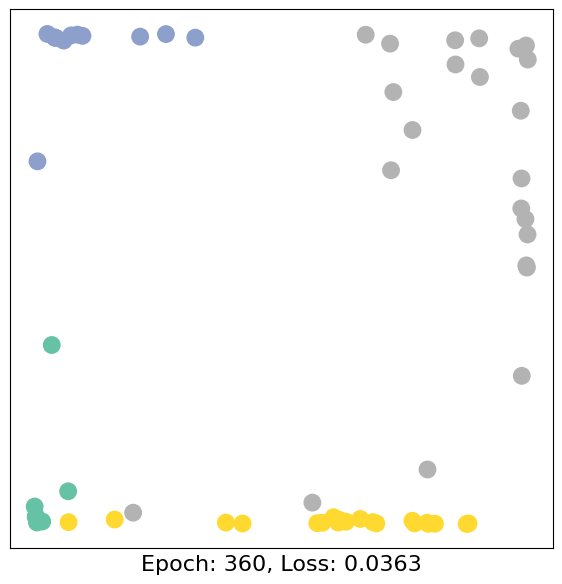

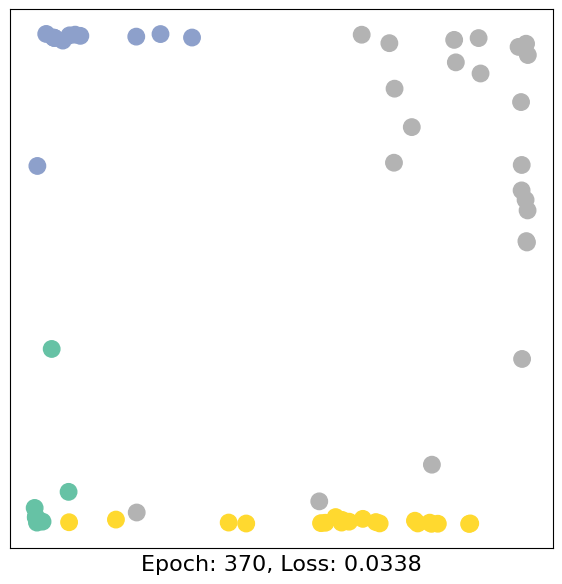

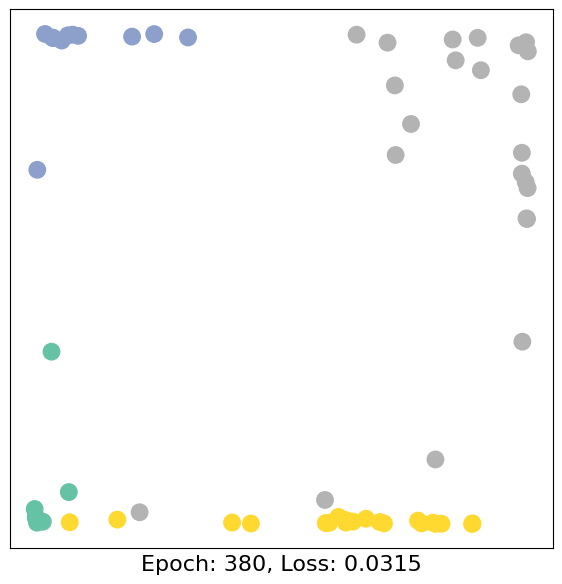

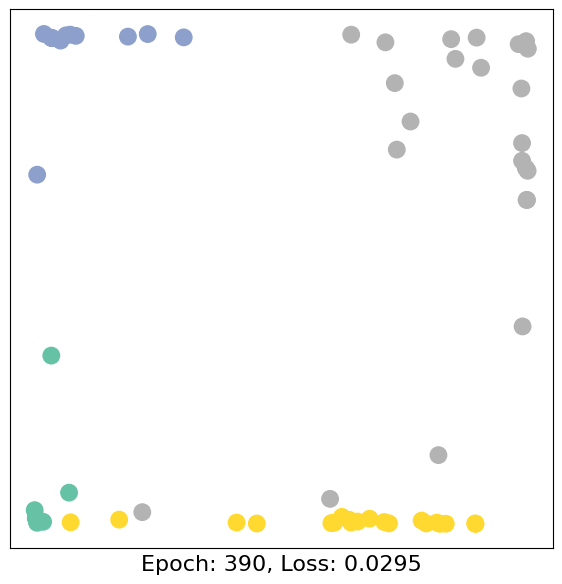

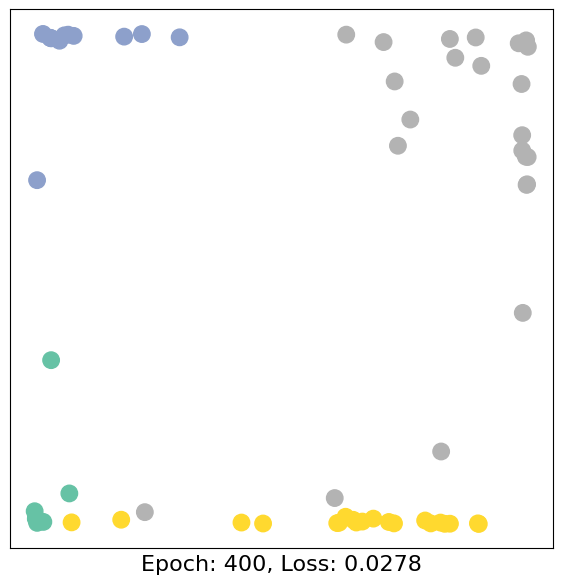

In [ ]:
import time
from IPython.display import Javascript  # Restrict height of output cell.
display(Javascript('''google.colab.output.setIframeHeight(0, true, {maxHeight: 430})'''))

model = GCN()
criterion = torch.nn.CrossEntropyLoss()  # Define loss criterion.
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)  # Define optimizer.

def train(data):
    optimizer.zero_grad()  # Clear gradients.
    out, h = model(data.x, data.edge_index)  # Perform a single forward pass.
    loss = criterion(out[data.train_mask], data.y[data.train_mask])  # Compute the loss solely based on the training nodes.
    loss.backward()  # Derive gradients.
    optimizer.step()  # Update parameters based on gradients.
    return loss, h

for epoch in range(401):
    loss, h = train(data)
    if epoch % 10 == 0:
        visualize_embedding(h, color=data.y, epoch=epoch, loss=loss)
        time.sleep(0.3)

In [ ]:
# Финальный ответ модели
out, h = model(data.x, data.edge_index)
h

tensor([[-0.9934, -0.9872],
        [-0.9999, -0.3140],
        [-0.9994,  0.9654],
        [-0.9988, -0.4219],
        [ 0.9873, -0.9900],
        [ 0.9968, -0.9972],
        [ 0.9968, -0.9972],
        [-0.9932, -0.0332],
        [-0.9872,  0.9821],
        [-0.9615,  0.9853],
        [ 0.9875, -0.9900],
        [-0.7699, -0.7664],
        [-0.9659, -0.6461],
        [-0.9932,  0.5391],
        [-0.9346,  0.9944],
        [-0.9332,  0.9944],
        [ 0.9983, -0.9938],
        [-0.9680, -0.5459],
        [-0.9310,  0.9950],
        [-0.9722,  0.4383],
        [-0.9238,  0.9945],
        [-0.9732, -0.5114],
        [-0.9316,  0.9944],
        [-0.0536,  0.9987],
        [ 0.9934,  0.9882],
        [ 0.9888,  0.9905],
        [-0.9477,  0.9978],
        [ 0.3735,  0.9940],
        [-0.7375,  0.9893],
        [-0.9560,  0.9992],
        [-0.9887,  0.9818],
        [ 0.6570,  0.9918],
        [-0.9997,  1.0000],
        [-1.0000,  1.0000]], grad_fn=<TanhBackward0>)

In [ ]:
# Проверим результаты на неразмеченных узлах
test_mask = torch.logical_not(data.train_mask)
test_mask

tensor([False,  True,  True,  True, False,  True,  True,  True, False,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True, False,  True,  True,  True,  True,  True,
         True,  True,  True,  True])

In [ ]:
# Финальный ответ модели
out, _ = model(data.x, data.edge_index)
# Предсказания модели
pred = out.argmax(dim=1)
test_correct = pred[test_mask] == data.y[test_mask]  # Проверям предсказания
test_acc = int(test_correct.sum()) / int(test_mask.sum())  # Доля правильных меток
test_acc

0.8

## Немного о тензорах



Tensors are the central data abstraction in PyTorch.

Математический объект $X$, который в каждом базисе представляется $(r+s)$-мерным массивом $X^{i_1 \ldots i_r}_{j_1 \ldots j_s}$ вещественных чисел, удовлетворяющих правилам преобразования  при смене базиса, называется тензором типа $(r,s)$. Число компонент тензора (набор чисел, которым представляется тензор в данном базисе) равно $n^{s+r}$.

Ранг тензора - $r+s$.

* Тензор $0$ ранга - скаляр.
* Тензор $1$ ранга - вектор.
* Тензор $2$ ранга - матрица.

In [ ]:
# Тензор 3 x 4, все элементы = 1
ones = torch.ones(3, 4)
print(ones)

# Тензор 3 x 4, все элементы = 0
zeros = torch.zeros(3, 4)
print(zeros)

# Тензор 3 x 4, элементы случайные числа от [0, 1)
random_tensor = torch.rand(3, 4)
print(random_tensor)

# Тензор 2 x 2 x 3, все элементы = 1
x = torch.ones(2, 2, 3)
print(x)

tensor([[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]])
tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]])
tensor([[0.5513, 0.5326, 0.5210, 0.0655],
        [0.9826, 0.9773, 0.1558, 0.6236],
        [0.9133, 0.5968, 0.7151, 0.8724]])
tensor([[[1., 1., 1.],
         [1., 1., 1.]],

        [[1., 1., 1.],
         [1., 1., 1.]]])


In [ ]:
print(x.shape)


torch.Size([2, 2, 3])


PyTorch tensor содержит элементы одного типа (dtype)

In [ ]:
# Тензор 3 x 4, все элементы = 0 (с плавающей запятой)
zeros = torch.zeros(3, 4, dtype=torch.float32)
print(zeros)
print(zeros.dtype)

# Тензор 3 x 4, все элементы = 0 (целые числа)
zeros = zeros.type(torch.long)
print(zeros)
print(zeros.dtype)

tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]])
torch.float32
tensor([[0, 0, 0, 0],
        [0, 0, 0, 0],
        [0, 0, 0, 0]])
torch.int64


## Создание объекта типа Data для PyTorch

In [ ]:
import numpy as np

In [ ]:
# Граф карате клуба
K = nx.karate_club_graph()
# Сделаем граф ориентированным
K = K.to_directed()

In [ ]:
# Преобразуем список рёбер в PyTorch tensor [2, len(списка рёбер)]
# Список рёбер графа
edge_list = [edg for edg in K.edges()]
print(len(edge_list))

156


In [ ]:
edge_list

[(0, 1),
 (0, 2),
 (0, 3),
 (0, 4),
 (0, 5),
 (0, 6),
 (0, 7),
 (0, 8),
 (0, 10),
 (0, 11),
 (0, 12),
 (0, 13),
 (0, 17),
 (0, 19),
 (0, 21),
 (0, 31),
 (1, 0),
 (1, 2),
 (1, 3),
 (1, 7),
 (1, 13),
 (1, 17),
 (1, 19),
 (1, 21),
 (1, 30),
 (2, 0),
 (2, 1),
 (2, 3),
 (2, 7),
 (2, 8),
 (2, 9),
 (2, 13),
 (2, 27),
 (2, 28),
 (2, 32),
 (3, 0),
 (3, 1),
 (3, 2),
 (3, 7),
 (3, 12),
 (3, 13),
 (4, 0),
 (4, 6),
 (4, 10),
 (5, 0),
 (5, 6),
 (5, 10),
 (5, 16),
 (6, 0),
 (6, 4),
 (6, 5),
 (6, 16),
 (7, 0),
 (7, 1),
 (7, 2),
 (7, 3),
 (8, 0),
 (8, 2),
 (8, 30),
 (8, 32),
 (8, 33),
 (9, 2),
 (9, 33),
 (10, 0),
 (10, 4),
 (10, 5),
 (11, 0),
 (12, 0),
 (12, 3),
 (13, 0),
 (13, 1),
 (13, 2),
 (13, 3),
 (13, 33),
 (14, 32),
 (14, 33),
 (15, 32),
 (15, 33),
 (16, 5),
 (16, 6),
 (17, 0),
 (17, 1),
 (18, 32),
 (18, 33),
 (19, 0),
 (19, 1),
 (19, 33),
 (20, 32),
 (20, 33),
 (21, 0),
 (21, 1),
 (22, 32),
 (22, 33),
 (23, 25),
 (23, 27),
 (23, 29),
 (23, 32),
 (23, 33),
 (24, 25),
 (24, 27),
 (24, 31),
 (25, 

In [ ]:
# транспонируем список и преобразуем в тензор
edge_index = torch.tensor(np.transpose(edge_list))
print(edge_index.shape)

torch.Size([2, 156])


In [ ]:
edge_index

tensor([[ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  1,  1,
          1,  1,  1,  1,  1,  1,  1,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  3,
          3,  3,  3,  3,  3,  4,  4,  4,  5,  5,  5,  5,  6,  6,  6,  6,  7,  7,
          7,  7,  8,  8,  8,  8,  8,  9,  9, 10, 10, 10, 11, 12, 12, 13, 13, 13,
         13, 13, 14, 14, 15, 15, 16, 16, 17, 17, 18, 18, 19, 19, 19, 20, 20, 21,
         21, 22, 22, 23, 23, 23, 23, 23, 24, 24, 24, 25, 25, 25, 26, 26, 27, 27,
         27, 27, 28, 28, 28, 29, 29, 29, 29, 30, 30, 30, 30, 31, 31, 31, 31, 31,
         31, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 33, 33, 33, 33, 33,
         33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33],
        [ 1,  2,  3,  4,  5,  6,  7,  8, 10, 11, 12, 13, 17, 19, 21, 31,  0,  2,
          3,  7, 13, 17, 19, 21, 30,  0,  1,  3,  7,  8,  9, 13, 27, 28, 32,  0,
          1,  2,  7, 12, 13,  0,  6, 10,  0,  6, 10, 16,  0,  4,  5, 16,  0,  1,
          2,  3,  0,  2, 30, 32, 33,  2, 33,  0,  4

In [ ]:
# Создадим матрицу с исходными признаками
x = torch.tensor(np.identity(34), dtype=torch.float32)

In [ ]:
# Эталонное разбиение на классы (ground truth)
y = torch.tensor([1, 1, 1, 1, 3, 3, 3, 1, 0, 1, 3, 1, 1, 1, 0, 0, 3, 1, 0, 1, 0, 1, 0, 0,
        2, 2, 0, 0, 2, 0, 0, 2, 0, 0])

In [ ]:
# Помечаем первый узел из каждого класса
train_mask = torch.zeros(y.size(0), dtype=torch.bool)
for i in range(int(y.max()) + 1):
  train_mask[(y == i).nonzero(as_tuple = False)[0]] = True

In [ ]:
from torch_geometric.data import Data

# Создаем объект типа Data
data2 = Data(x=x, edge_index=edge_index, y=y, train_mask=train_mask)

In [ ]:
# Статистика по графу
print(f'Number of nodes: {data2.num_nodes}')
print(f'Number of edges: {data2.num_edges}')
print(f'Average node degree: {data2.num_edges / data2.num_nodes:.2f}')
print(f'Number of training nodes: {data2.train_mask.sum()}')
print(f'Training node label rate: {int(data2.train_mask.sum()) / data2.num_nodes:.2f}')
print(f'Has isolated nodes: {data2.has_isolated_nodes()}')
print(f'Has self-loops: {data2.has_self_loops()}')
print(f'Is undirected: {data2.is_undirected()}')

Number of nodes: 34
Number of edges: 156
Average node degree: 4.59
Number of training nodes: 4
Training node label rate: 0.12
Has isolated nodes: False
Has self-loops: False
Is undirected: True


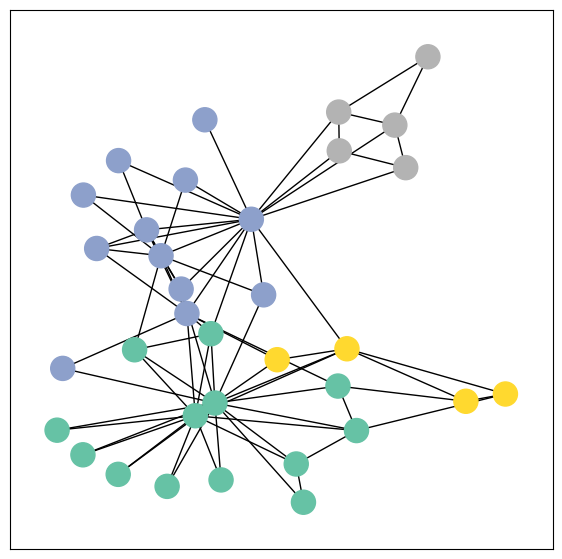

In [ ]:
# Нарисуем эталонное разбиение
from torch_geometric.utils import to_networkx

g = to_networkx(data2, to_undirected=True)
visualize_graph(g, color=data2.y)

In [ ]:
# Создадим 3-х слойную GCN : 34 -> 4 -> 4 -> 2
# Функция активации - tahn
# Линейный классификатор по финальным признакам
import torch
from torch.nn import Linear
from torch_geometric.nn import GCNConv

num_features = 34
num_classes = 4


class GCN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        torch.manual_seed(1234)
        self.conv1 = GCNConv(num_features, 4)
        self.conv2 = GCNConv(4, 4)
        self.conv3 = GCNConv(4, 2)
        self.classifier = Linear(2, num_classes)

    def forward(self, x, edge_index):
        h = self.conv1(x, edge_index)
        h = h.tanh()
        h = self.conv2(h, edge_index)
        h = h.tanh()
        h = self.conv3(h, edge_index)
        h = h.tanh()  # Финальные признаки

        # Линейный классификатор
        out = self.classifier(h)

        return out, h

model = GCN()
print(model)

GCN(
  (conv1): GCNConv(34, 4)
  (conv2): GCNConv(4, 4)
  (conv3): GCNConv(4, 2)
  (classifier): Linear(in_features=2, out_features=4, bias=True)
)


<IPython.core.display.Javascript object>

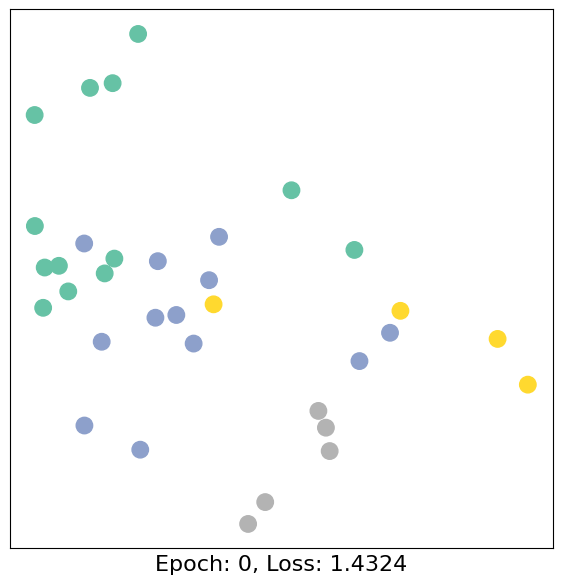

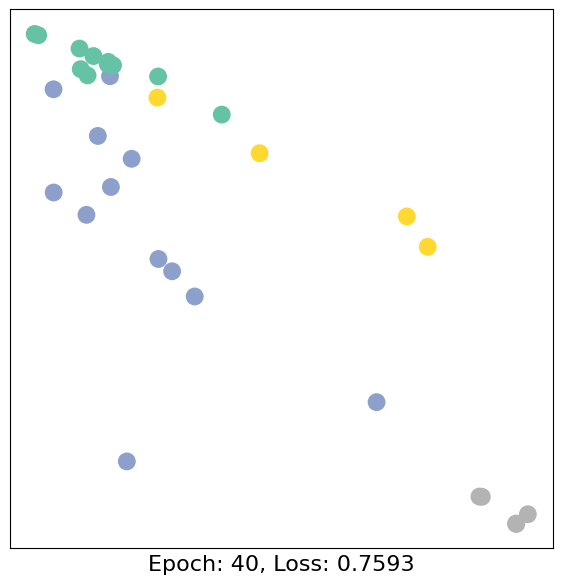

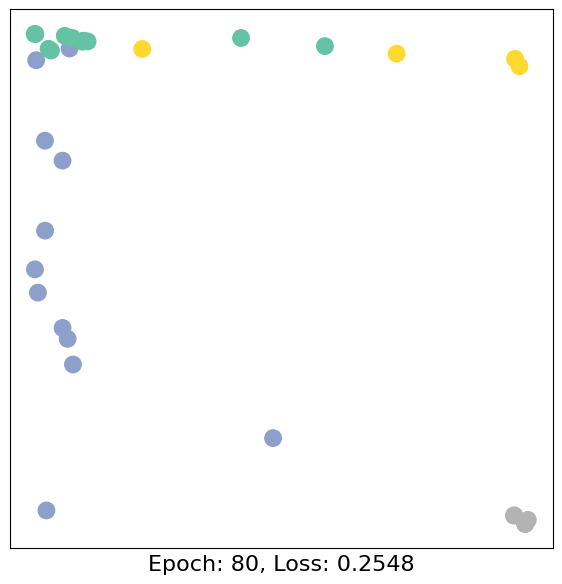

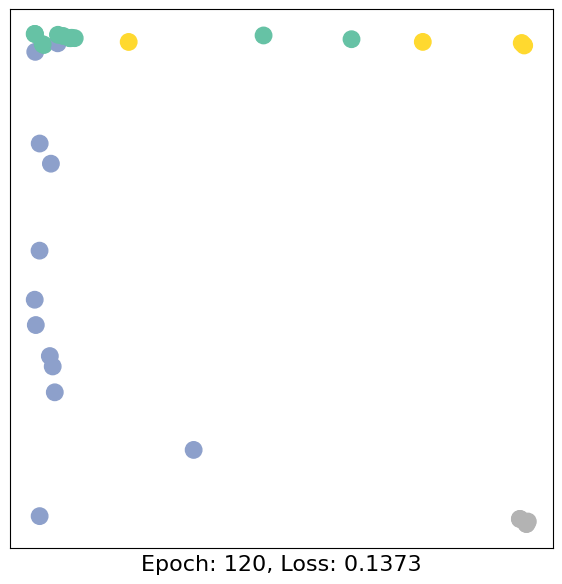

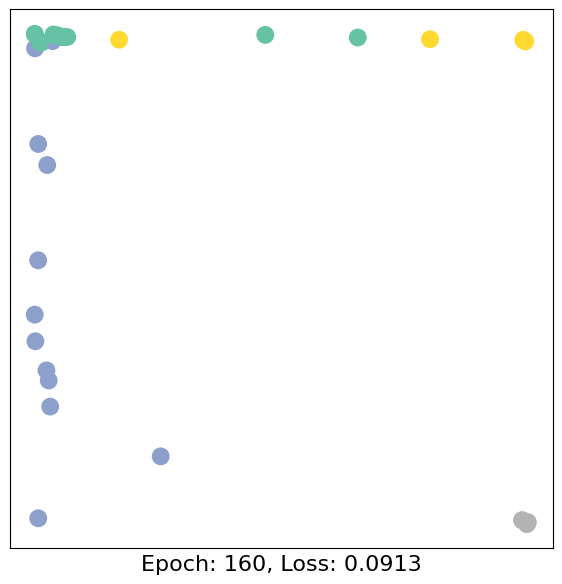

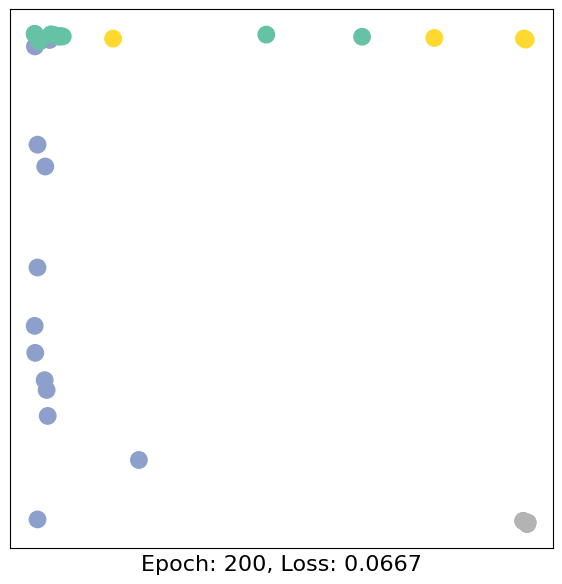

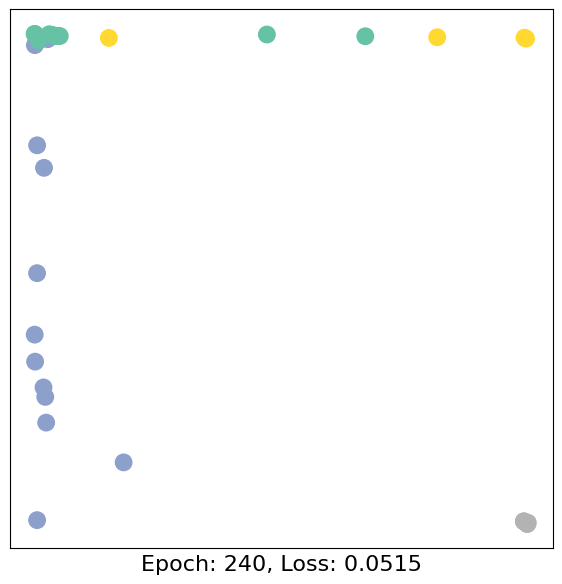

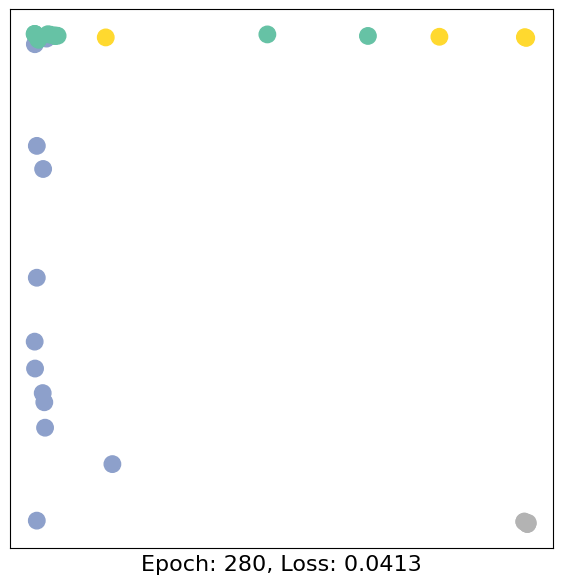

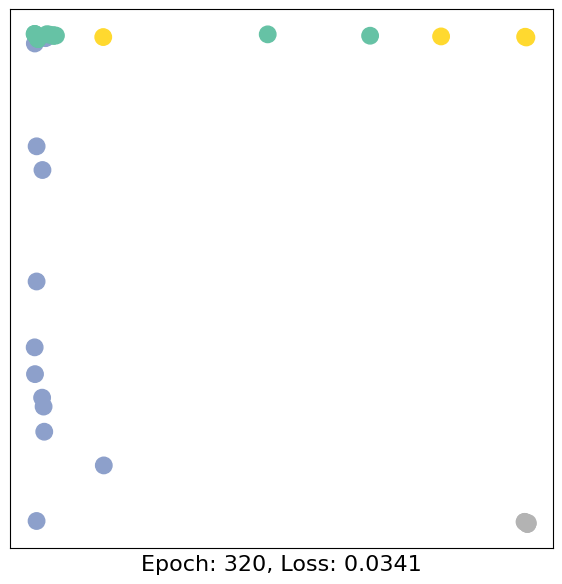

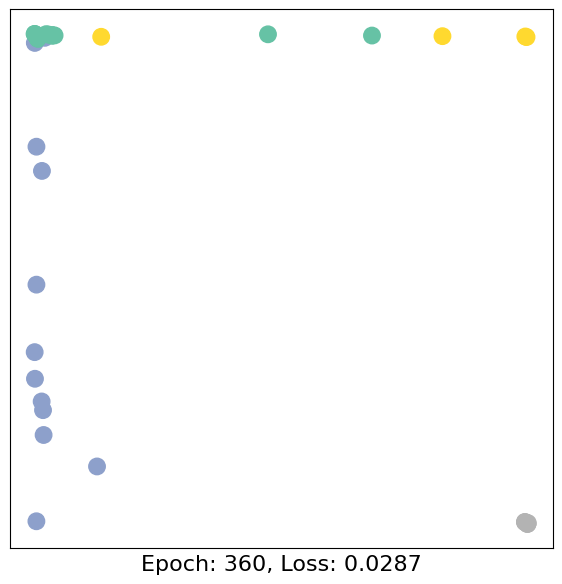

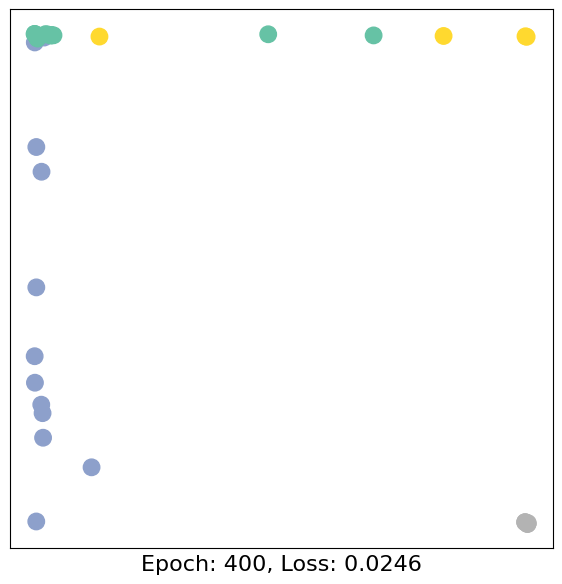

In [ ]:
import time
from IPython.display import Javascript  # Restrict height of output cell.
display(Javascript('''google.colab.output.setIframeHeight(0, true, {maxHeight: 430})'''))

model = GCN()
criterion = torch.nn.CrossEntropyLoss()  # Функция потерь
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)  # Оптимизация

def train(data):
    optimizer.zero_grad()  # Clear gradients.
    out, h = model(data.x, data.edge_index)  # Проход вперед
    loss = criterion(out[data.train_mask], data.y[data.train_mask])  # Функцию потерь считаем только на размеченных узлах!
    loss.backward()  # Проход назад
    optimizer.step()  # Обновляем параметры (веса)
    return loss, h

for epoch in range(401):
    loss, h = train(data2)
    if epoch % 40 == 0:
        visualize_embedding(h, color=data2.y, epoch=epoch, loss=loss)
        time.sleep(0.3)

In [ ]:
# Проверим результаты на неразмеченных узлах
test2_mask = torch.logical_not(data2.train_mask)
test2_mask

tensor([False,  True,  True,  True, False,  True,  True,  True, False,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True, False,  True,  True,  True,  True,  True,
         True,  True,  True,  True])

In [ ]:
# Финальный ответ модели
out, _ = model(data2.x, data2.edge_index)
# Предсказания модели
pred2 = out.argmax(dim=1)
test2_correct = pred[test2_mask] == data2.y[test_mask]  # Проверям предсказания
test2_acc = int(test2_correct.sum()) / int(test2_mask.sum())  # Доля правильных меток
test2_acc

0.8

Text(0.5, 1.0, '"Ground truth" разделение')

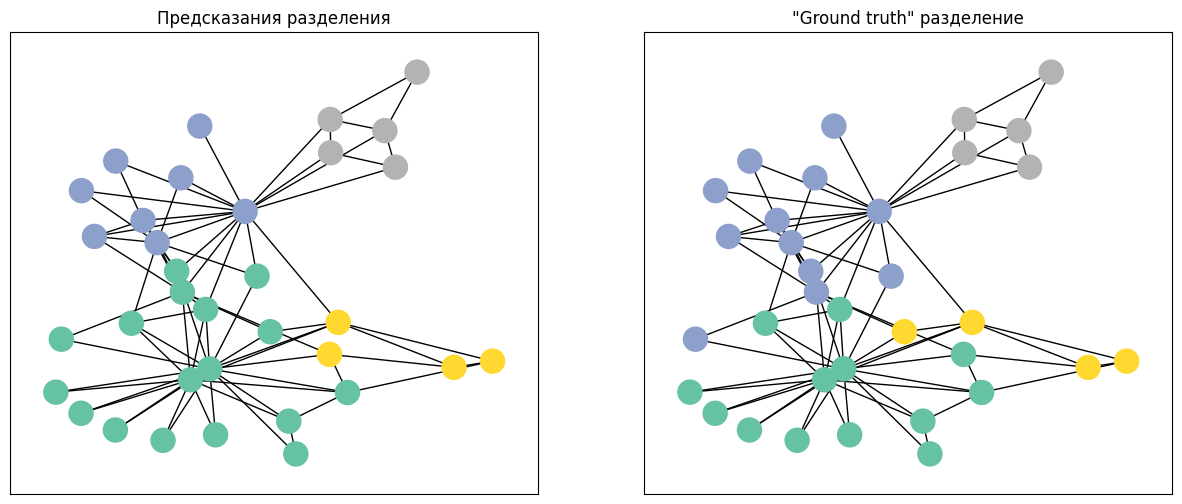

In [ ]:
# Сравним предсказание с ground-truth разбиением
fig = plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
nx.draw_networkx(g, pos=nx.spring_layout(g, seed=42), with_labels=False,
                 node_color=pred, cmap="Set2")
plt.title('Предсказания разделения')

plt.subplot(1, 2, 2)
nx.draw_networkx(g, pos=nx.spring_layout(g, seed=42), with_labels=False,
                 node_color=data2.y, cmap="Set2")
plt.title('"Ground truth" разделение')


# Задание

- Импортируйте датасат Dolphin Social Network
- На основе датасета создайте объект Data для работы с PyG.
Выберите по одному узлу к каждом классе и пометьте этот узел.
- Постройте 3-х слойную сеть по образцу сети из этого Colab-а.
- Выполните классификацию узлов по построенной сети. Какая доля узлов была правильно классифицированна?
- Измените архитертуру сети: число слоев (от 1 до 3-х), функцию активации (tahn, relu, softmax). Количество эпох - не более 400. Наилучший результат запишите в таблицу  [Leaderboards 2025](https://disk.yandex.ru/edit/d/XabL12qmiobJ7VF-mxBEuCPegnqahzm72s0qoIz-cKg6VDVpNkY2eHNFZw) .

In [ ]:
import torch_geometric.datasets as datasets
print(datasets.__all__)

['KarateClub', 'TUDataset', 'GNNBenchmarkDataset', 'Planetoid', 'NELL', 'CitationFull', 'CoraFull', 'Coauthor', 'Amazon', 'PPI', 'Reddit', 'Reddit2', 'Flickr', 'Yelp', 'AmazonProducts', 'QM7b', 'QM9', 'MD17', 'ZINC', 'AQSOL', 'MoleculeNet', 'PCQM4Mv2', 'Entities', 'RelLinkPredDataset', 'GEDDataset', 'AttributedGraphDataset', 'MNISTSuperpixels', 'FAUST', 'DynamicFAUST', 'ShapeNet', 'ModelNet', 'MedShapeNet', 'CoMA', 'SHREC2016', 'TOSCA', 'PCPNetDataset', 'S3DIS', 'GeometricShapes', 'BitcoinOTC', 'GDELTLite', 'ICEWS18', 'GDELT', 'WILLOWObjectClass', 'PascalVOCKeypoints', 'PascalPF', 'SNAPDataset', 'SuiteSparseMatrixCollection', 'WordNet18', 'WordNet18RR', 'FB15k_237', 'WikiCS', 'WebKB', 'WikipediaNetwork', 'HeterophilousGraphDataset', 'Actor', 'UPFD', 'GitHub', 'FacebookPagePage', 'LastFMAsia', 'DeezerEurope', 'GemsecDeezer', 'Twitch', 'Airports', 'LRGBDataset', 'MalNetTiny', 'OMDB', 'PolBlogs', 'EmailEUCore', 'LINKXDataset', 'EllipticBitcoinDataset', 'EllipticBitcoinTemporalDataset', 'D

In [ ]:
!pip install gdown  # Установите, если не установлено
import gdown

file_id = '1K0GoVwxP6ebW9-P4cOTyijBHvuatrFnn'
gdown.download(f'https://drive.google.com/uc?id={file_id}', 'soc-dolphins-nodes.csv', quiet=False)

file_id = '1TLqB48bENiA0xUTpbPwFhl7shVQaP1SJ'
gdown.download(f'https://drive.google.com/uc?id={file_id}', 'soc-dolphins.csv', quiet=False)

Downloading...
From: https://drive.google.com/uc?id=1K0GoVwxP6ebW9-P4cOTyijBHvuatrFnn
To: /content/soc-dolphins-nodes.csv
100%|██████████| 753/753 [00:00<00:00, 872kB/s]
Downloading...
From: https://drive.google.com/uc?id=1TLqB48bENiA0xUTpbPwFhl7shVQaP1SJ
To: /content/soc-dolphins.csv
100%|██████████| 1.08k/1.08k [00:00<00:00, 2.10MB/s]


'soc-dolphins.csv'

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv('soc-dolphins.csv', header=0, sep=';')
df.head()

,source,target
0,10,0
1,14,0
2,15,0
3,40,0
4,42,0


In [ ]:
df_nodes = pd.read_csv('soc-dolphins-nodes.csv',header=0, sep=';')
df_nodes.head()

,id,label,group
0,0,Beak,0
1,1,Beescratch,2
2,2,Bumper,0
3,3,CCL,3
4,4,Cross,1


In [ ]:
gr_df = nx.from_pandas_edgelist(df, "source", "target")
node_attrs = df_nodes.set_index('id')[['label', 'group']].to_dict('index')
nx.set_node_attributes(gr_df, node_attrs)

In [ ]:
nodes_by_group = {}
for id, row in df_nodes.iterrows():
    group = row['group']
    node_id = row['id']
    if group not in nodes_by_group:
        nodes_by_group[group] = set()
    nodes_by_group[group].add(node_id)

list_of_groups = list(nodes_by_group.values())

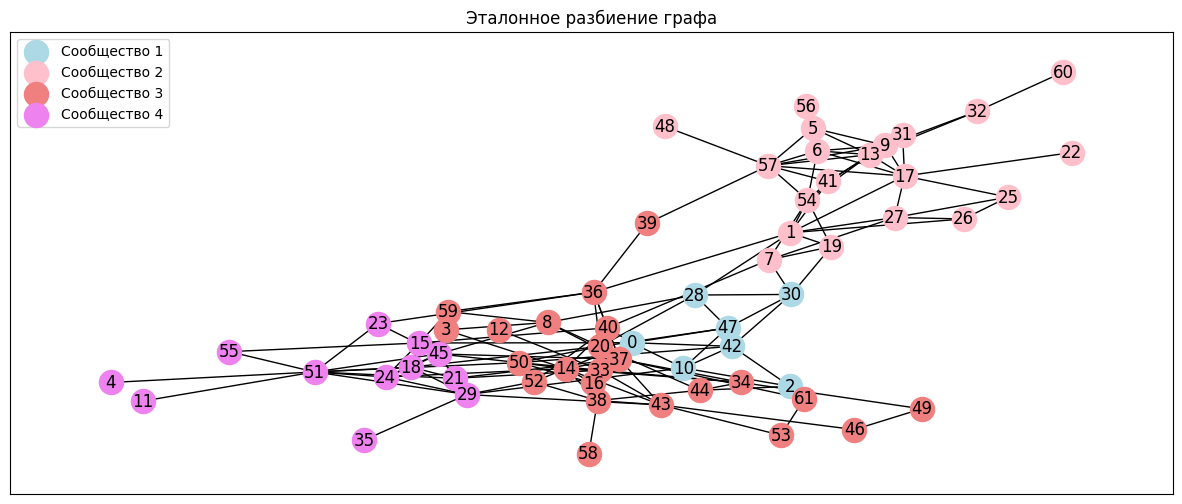

In [ ]:
pos = nx.spring_layout(gr_df)
plt.figure(figsize=(15, 6))

colors = ['lightblue', 'pink', 'lightcoral', 'violet']

for cluster, node_list in enumerate(list_of_groups):
    nx.draw_networkx_nodes(gr_df, pos, nodelist=list(node_list), node_color=colors[cluster], label=f'Сообщество {cluster+1}')

nx.draw_networkx_edges(gr_df, pos)
nx.draw_networkx_labels(gr_df, pos)

plt.title('Эталонное разбиение графа')
plt.legend()

In [ ]:
from torch_geometric.utils import from_networkx

In [ ]:
num_nodes = len(gr_df.nodes())
data = from_networkx(gr_df)
print(data)
data.x = torch.eye(num_nodes)
data.y = torch.tensor([node_attrs[node]['group'] for node in gr_df.nodes()])
data.num_classes = len(torch.unique(data.y))
data.num_features = num_nodes

print(f'Dataset: Dolphin Social Network')
print(f'Number of features: {data.num_features}')
print(f'Number of classes: {data.num_classes}')
print(data)


Data(edge_index=[2, 318], label=[62], group=[62], num_nodes=62)
Dataset: Dolphin Social Network
Number of features: 62
Number of classes: 4
Data(edge_index=[2, 318], label=[62], group=[62], num_nodes=62, x=[62, 62], y=[62], num_classes=4, num_features=62)


In [ ]:
print(f'Number of nodes: {data.num_nodes}')
print(f'Number of edges: {data.num_edges}')
print(f'Average node degree: {data.num_edges / data.num_nodes:.2f}')
print(f'Number of training nodes: {data.group.numel()}')
print(f'Training node label rate: {int(data.group.numel()) / data.num_nodes:.2f}')
print(f'Has isolated nodes: {data.has_isolated_nodes()}')
print(f'Has self-loops: {data.has_self_loops()}')
print(f'Is undirected: {data.is_undirected()}')

Number of nodes: 62
Number of edges: 318
Average node degree: 5.13
Number of training nodes: 62
Training node label rate: 1.00
Has isolated nodes: False
Has self-loops: False
Is undirected: True


In [ ]:
#chose node from each group
train_mask = torch.zeros(data.num_nodes, dtype=bool)
for group in range(data.num_classes):
    group_nodes = torch.where(data.y == group)[0].tolist()
    train_mask[group_nodes[0]] = True

data.train_mask = train_mask

print(f'Number of training nodes: {data.train_mask.sum()}')
print(f'Training node label rate: {int(data.train_mask.sum()) / data.num_nodes:.2f}')

Number of training nodes: 4
Training node label rate: 0.06


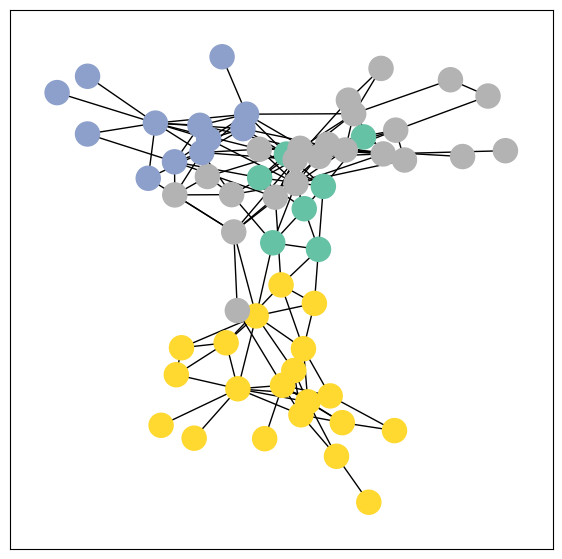

In [ ]:
G = to_networkx(data, to_undirected=True)
visualize_graph(G, color=data.y)

In [ ]:
class GCN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        torch.manual_seed(1234)
        self.conv1 = GCNConv(data.num_features, 4)
        self.conv2 = GCNConv(4, 4)
        self.conv3 = GCNConv(4, 2)
        self.classifier = Linear(2, data.num_classes)

    def forward(self, x, edge_index):
        h = self.conv1(x, edge_index)
        h = h.tanh()
        h = self.conv2(h, edge_index)
        h = h.tanh()
        h = self.conv3(h, edge_index)
        h = h.tanh()  # Финальные признаки

        # Линейный классификатор
        out = self.classifier(h)

        return out, h

model = GCN()
print(model)

GCN(
  (conv1): GCNConv(62, 4)
  (conv2): GCNConv(4, 4)
  (conv3): GCNConv(4, 2)
  (classifier): Linear(2, 4, bias=True)
)


<IPython.core.display.Javascript object>

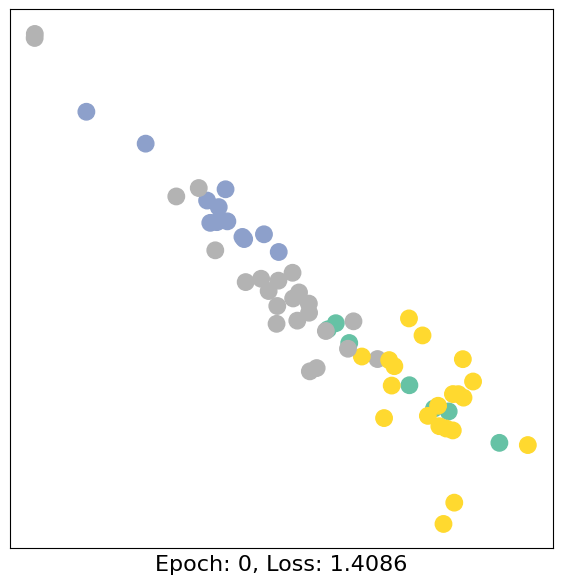

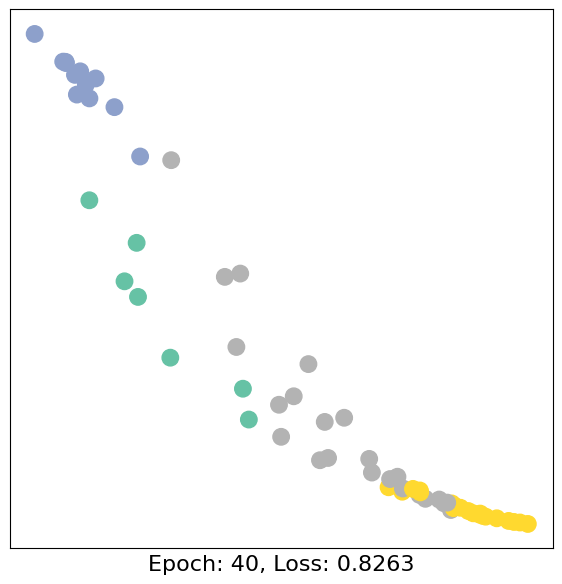

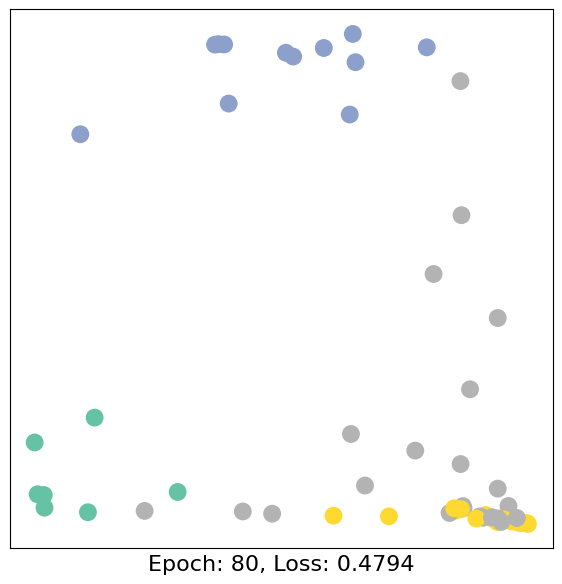

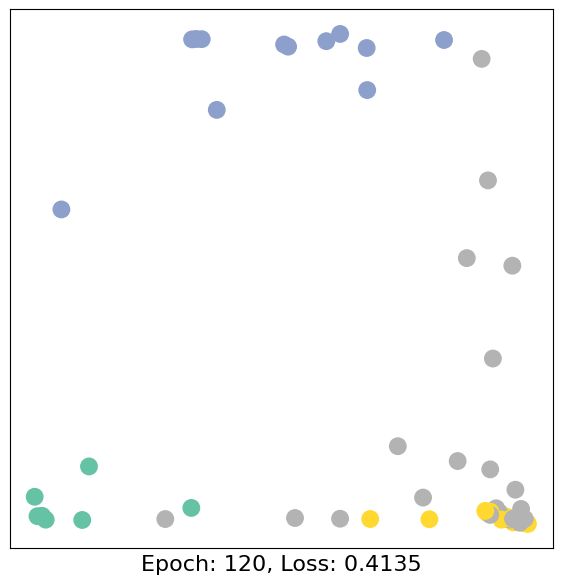

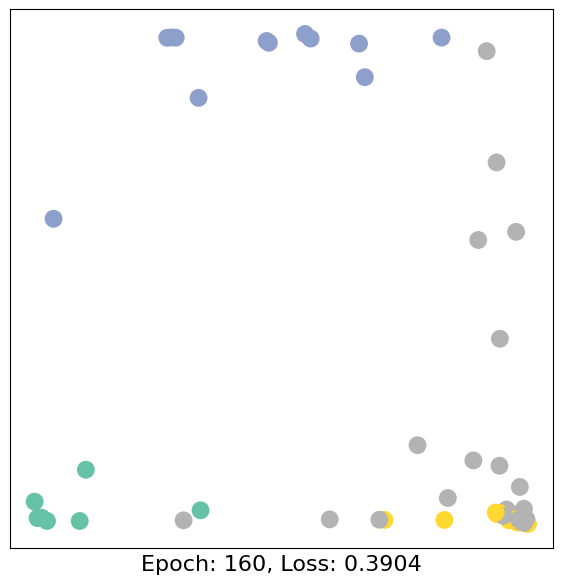

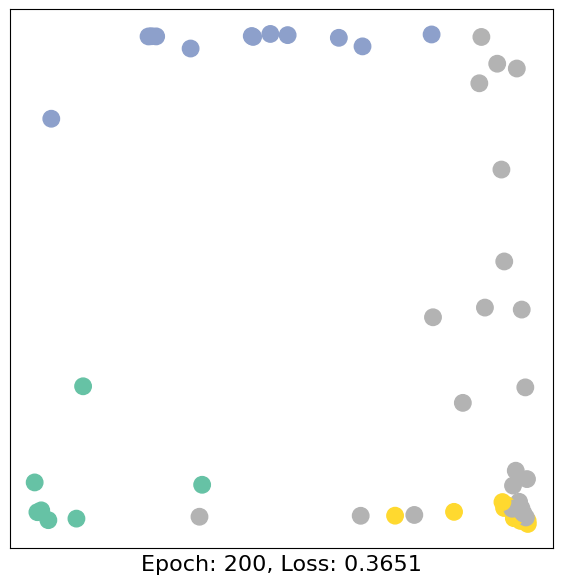

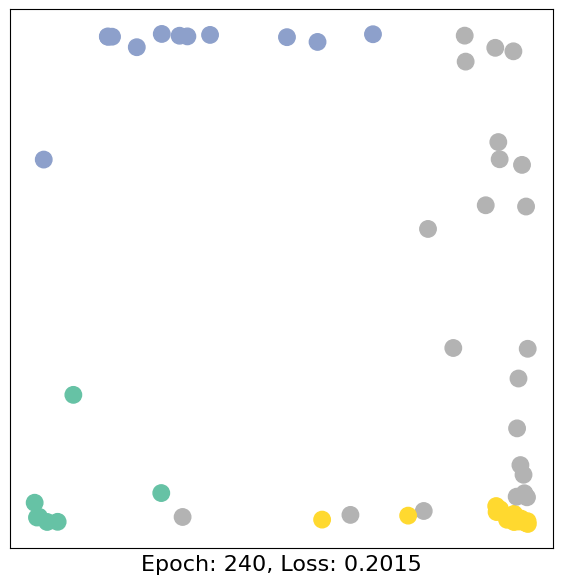

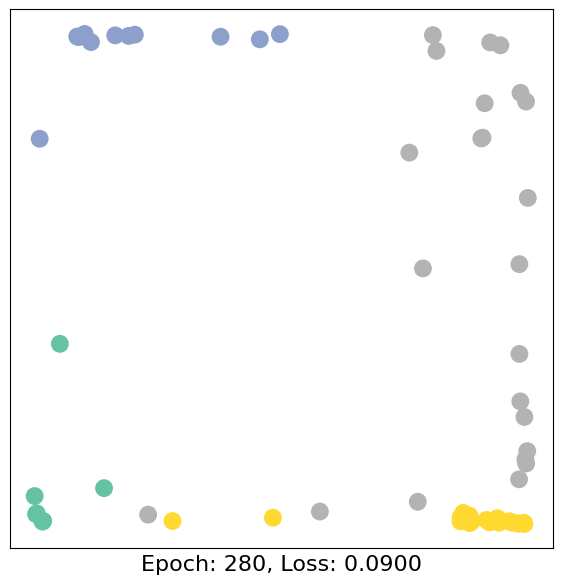

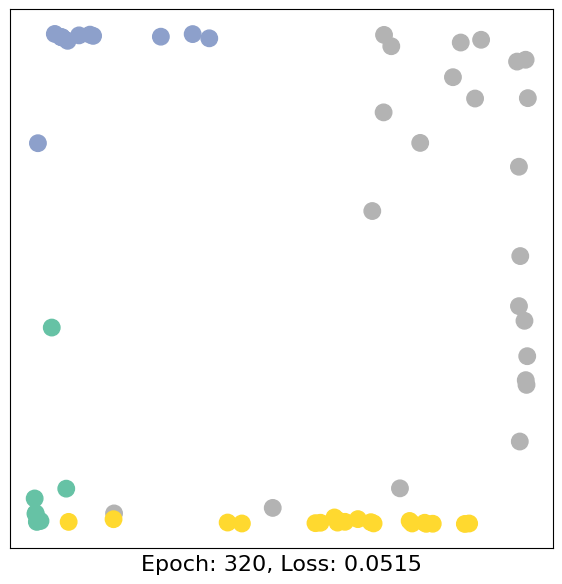

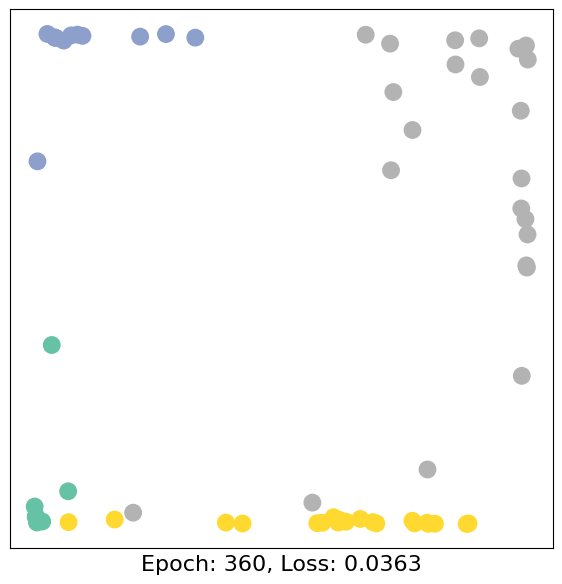

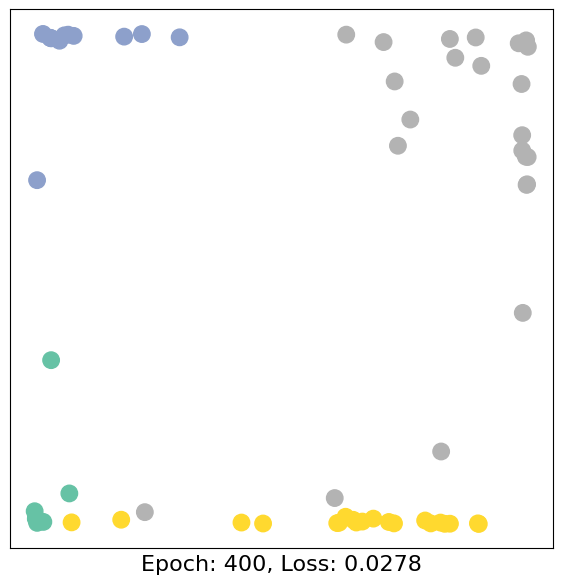

In [ ]:
import time
from IPython.display import Javascript  # Restrict height of output cell.
display(Javascript('''google.colab.output.setIframeHeight(0, true, {maxHeight: 430})'''))

model = GCN()
criterion = torch.nn.CrossEntropyLoss()  # Функция потерь
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)  # Оптимизация

def train(data):
    optimizer.zero_grad()  # Clear gradients.
    out, h = model(data.x, data.edge_index)  # Проход вперед
    loss = criterion(out[data.train_mask], data.y[data.train_mask])  # Функцию потерь считаем только на размеченных узлах!
    loss.backward()  # Проход назад
    optimizer.step()  # Обновляем параметры (веса)
    return loss, h
for epoch in range(401):
    loss, h = train(data)
    if epoch % 40 == 0:
        visualize_embedding(h, color=data.y, epoch=epoch, loss=loss)
        time.sleep(0.3)

In [ ]:
# Финальный ответ модели
out, h = model(data.x, data.edge_index)
h

tensor([[-0.9953, -0.9482],
        [-0.9289, -0.3332],
        [ 0.9907,  0.9739],
        [-0.8608,  0.9969],
        [ 0.7044,  0.9030],
        [-0.9907, -0.9785],
        [-0.9902, -0.9752],
        [ 0.8006, -0.9997],
        [-0.1579, -0.9940],
        [-0.8458, -0.9933],
        [ 0.3305, -0.9900],
        [ 0.2295, -0.9962],
        [-0.8551, -0.8755],
        [ 0.6819,  0.9795],
        [ 0.3063, -0.9938],
        [-0.0701, -0.9979],
        [-0.9601, -0.9914],
        [ 0.6482, -0.7027],
        [-0.5492, -0.9516],
        [ 0.4138,  0.9668],
        [ 0.7866,  0.9855],
        [ 0.2617,  0.9970],
        [-0.9621,  0.9999],
        [-0.9292,  0.9823],
        [ 0.6843, -0.9987],
        [ 0.6460, -0.9941],
        [ 0.6635, -0.9992],
        [ 0.5839, -0.9856],
        [ 0.7968, -0.9974],
        [ 0.6070, -0.9975],
        [-0.6449, -0.9825],
        [-0.9854, -0.9953],
        [ 0.4729,  0.5450],
        [ 0.9607,  0.9620],
        [-0.5644,  0.9994],
        [ 0.4585, -0

In [ ]:
# Проверим результаты на неразмеченных узлах
test_mask = torch.logical_not(data.train_mask)
test_mask

tensor([False,  True, False, False,  True,  True,  True, False,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True])

In [ ]:
# Финальный ответ модели
out, _ = model(data.x, data.edge_index)
# Предсказания модели
pred = out.argmax(dim=1)
test_correct = pred[test_mask] == data.y[test_mask]  # Проверям предсказания
test_acc = int(test_correct.sum()) / int(test_mask.sum())  # Доля правильных меток
test_acc

0.9137931034482759

In [ ]:
import torch.nn.functional as F

In [ ]:
# Базовая 3-х слойная модель
class GCN(torch.nn.Module):
    def __init__(self, num_layers=3, activation='tanh'):
        super().__init__()
        torch.manual_seed(1234)
        self.num_layers = num_layers
        self.activation = activation
        self.conv1 = GCNConv(data.num_features, 4)
        if num_layers >= 2:
            self.conv2 = GCNConv(4, 4)
        if num_layers >= 3:
            self.conv3 = GCNConv(4, 2)
        self.classifier = Linear(2 if num_layers >= 3 else 4, data.num_classes)

    def forward(self, x, edge_index):
        h = self.conv1(x, edge_index)
        if self.activation == 'tanh':
            h = h.tanh()
        elif self.activation == 'relu':
            h = F.relu(h)
        elif self.activation == 'softmax':
            h = F.softmax(h, dim=1)

        if self.num_layers >= 2:
            h = self.conv2(h, edge_index)
            if self.activation == 'tanh':
                h = h.tanh()
            elif self.activation == 'relu':
                h = F.relu(h)
            elif self.activation == 'softmax':
                h = F.softmax(h, dim=1)

        if self.num_layers >= 3:
            h = self.conv3(h, edge_index)
            if self.activation == 'tanh':
                h = h.tanh()
            elif self.activation == 'relu':
                h = F.relu(h)
            elif self.activation == 'softmax':
                h = F.softmax(h, dim=1)

        out = self.classifier(h)
        return out, h

In [ ]:
def train(data):
    optimizer.zero_grad()  # Clear gradients.
    out, h = model(data.x, data.edge_index)  # Проход вперед
    loss = criterion(out[data.train_mask], data.y[data.train_mask])  # Функцию потерь считаем только на размеченных узлах!
    loss.backward()  # Проход назад
    optimizer.step()  # Обновляем параметры (веса)
    return loss, h

In [ ]:
def visualize_embedding(h, color, epoch=None, loss=None, num_layers=None, activation=None):
    plt.figure(figsize=(7,7))
    plt.xticks([])
    plt.yticks([])
    h = h.detach().cpu().numpy()
    plt.scatter(h[:, 0], h[:, 1], s=140, c=color, cmap="Set2")
    text = f'Epoch: {epoch}, Loss: {loss:.4f}'
    if num_layers is not None and activation is not None:
        text += f', Layers: {num_layers}, Activation: {activation}'
    plt.xlabel(text, fontsize=16)
    plt.show()

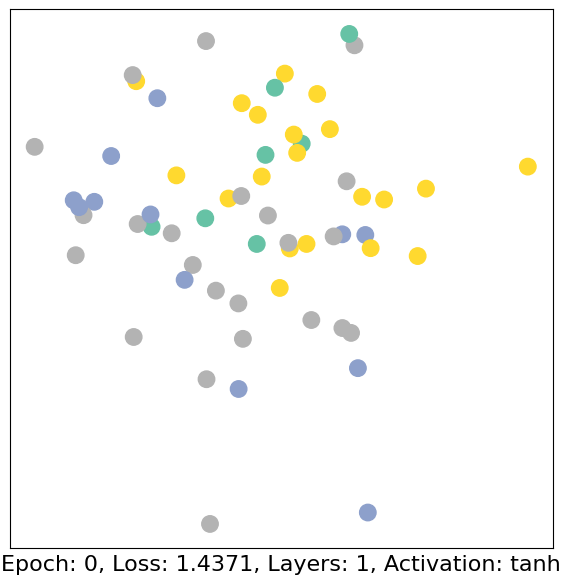

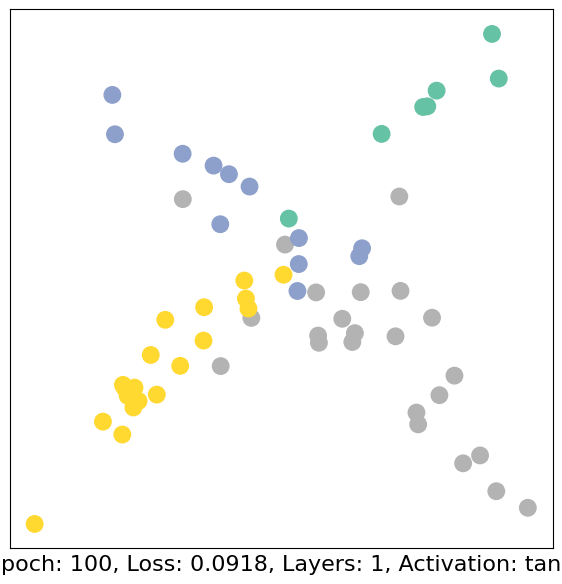

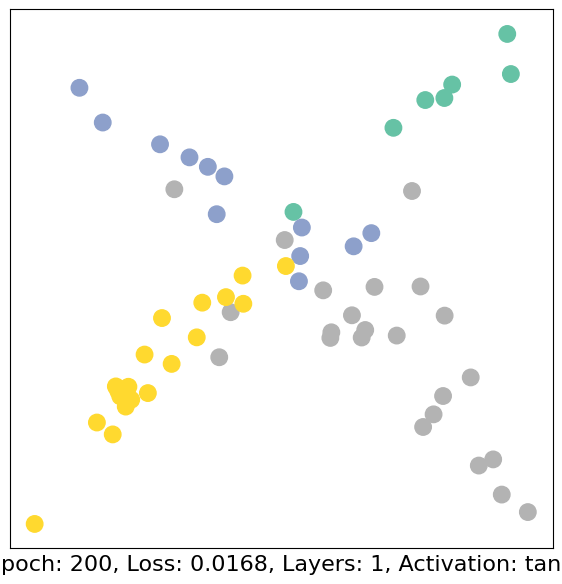

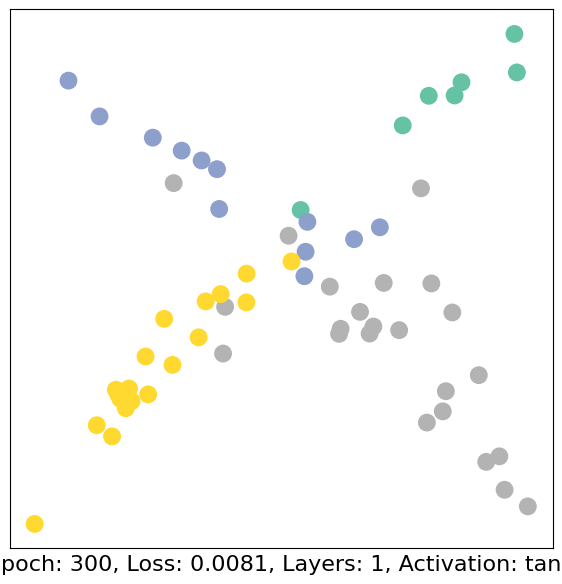

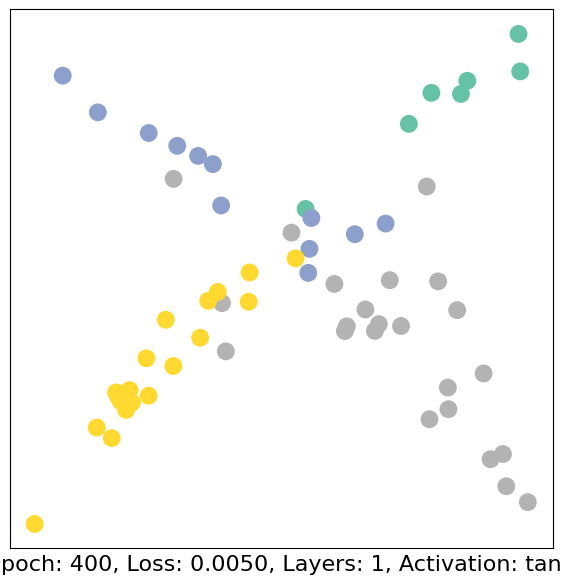

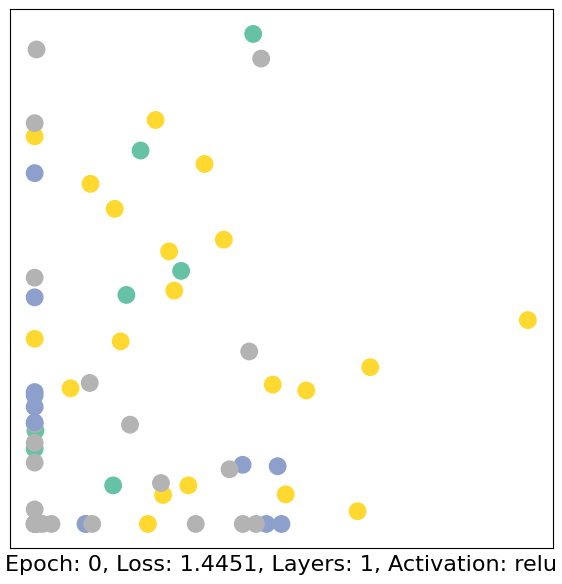

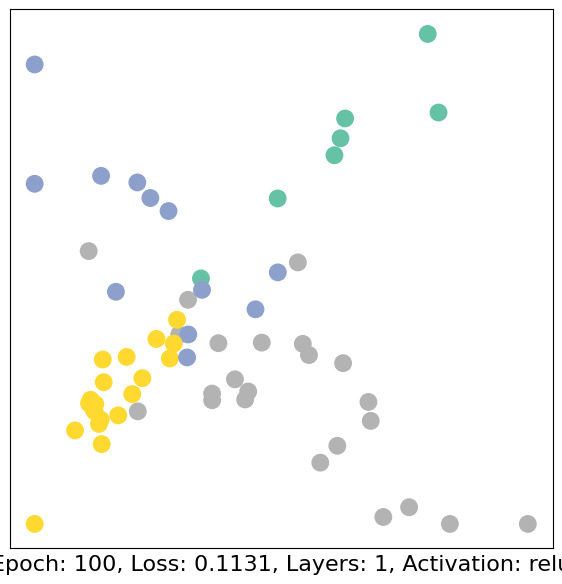

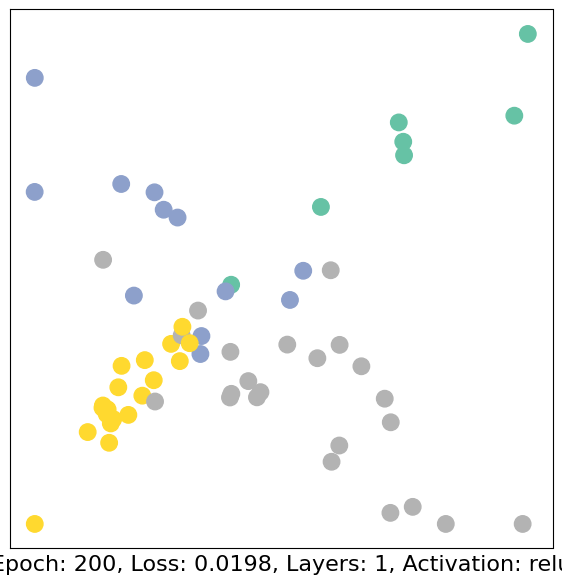

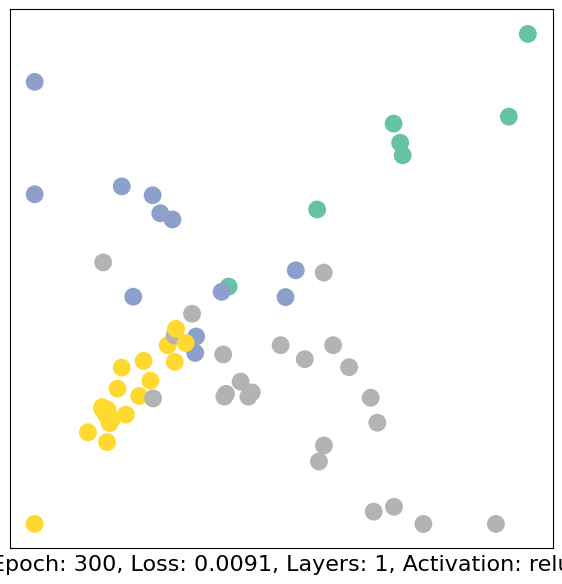

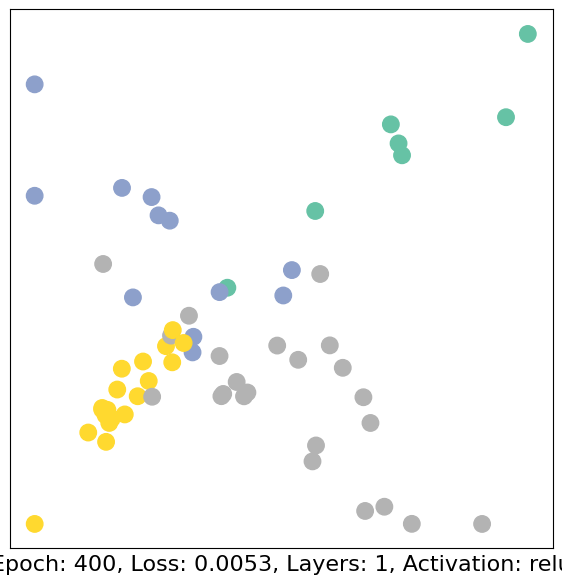

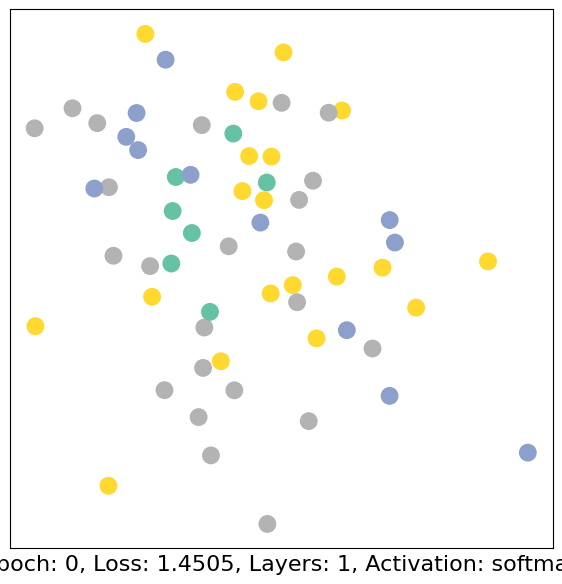

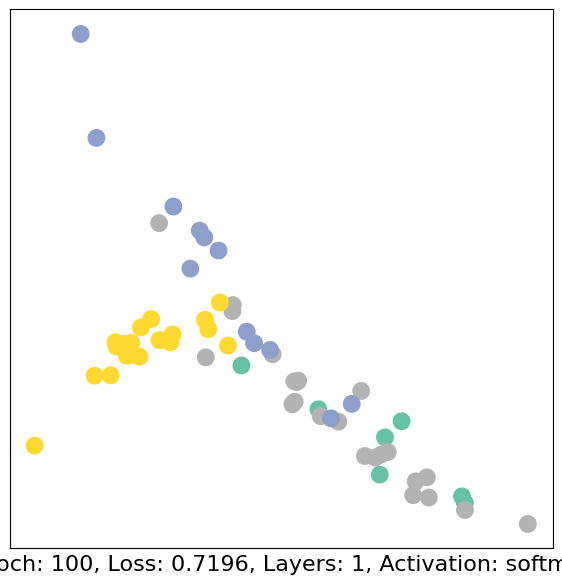

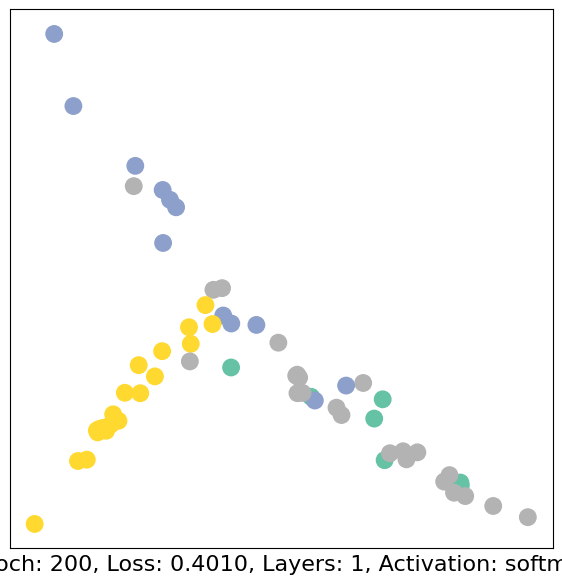

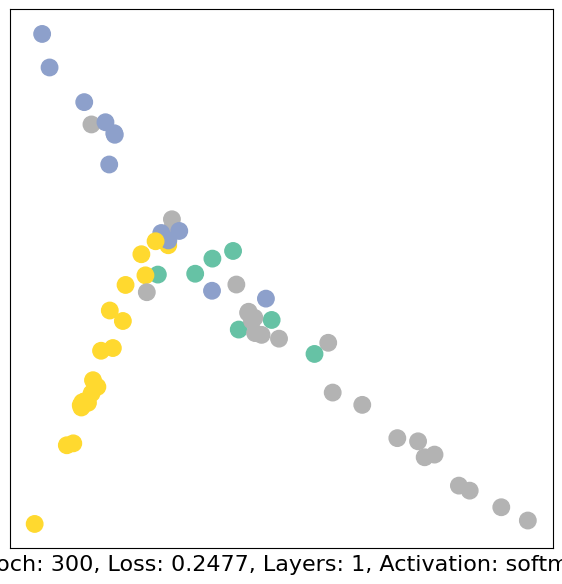

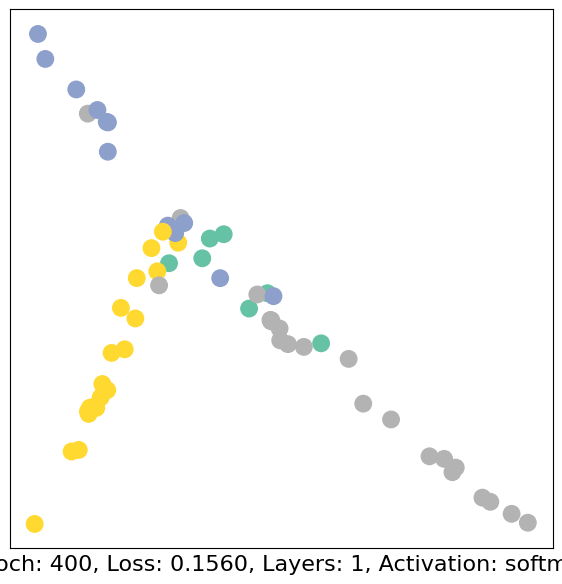

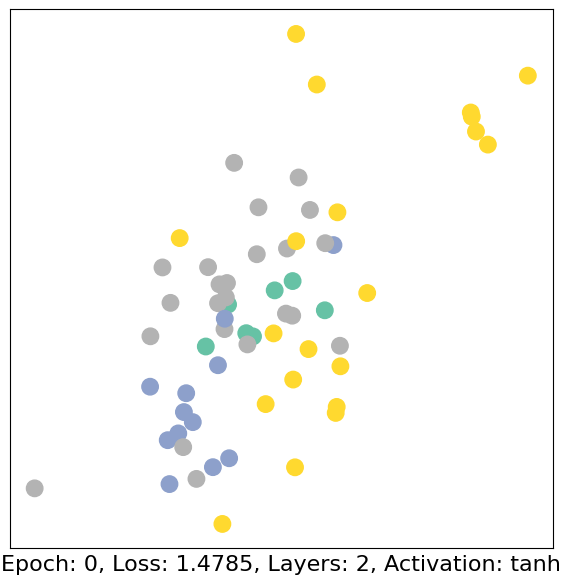

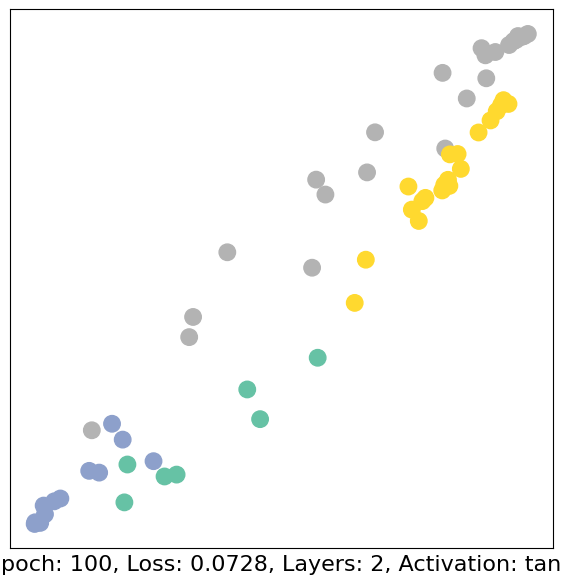

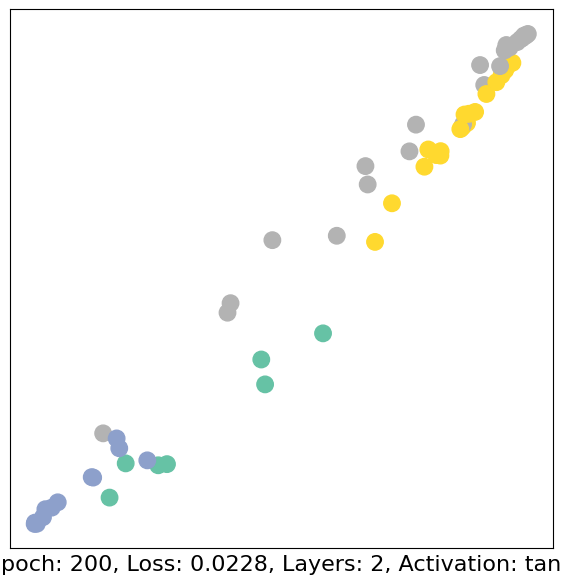

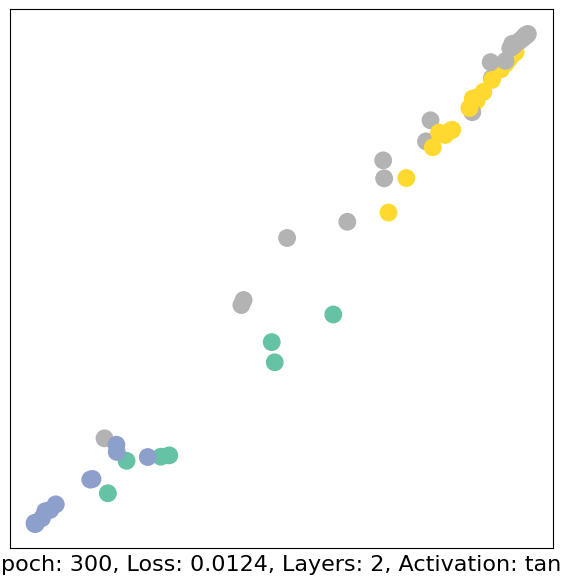

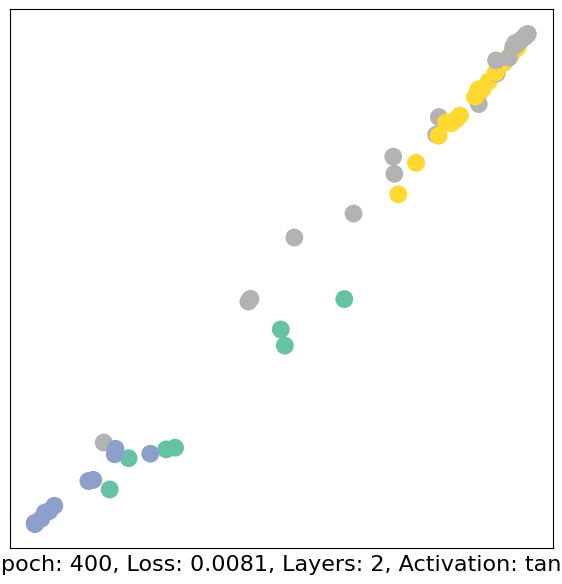

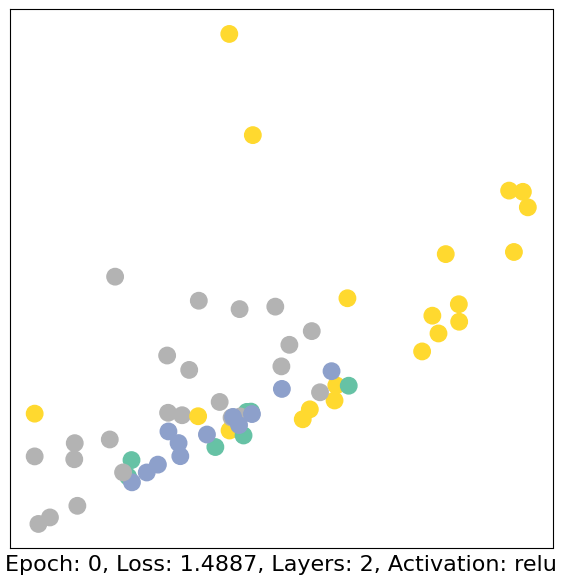

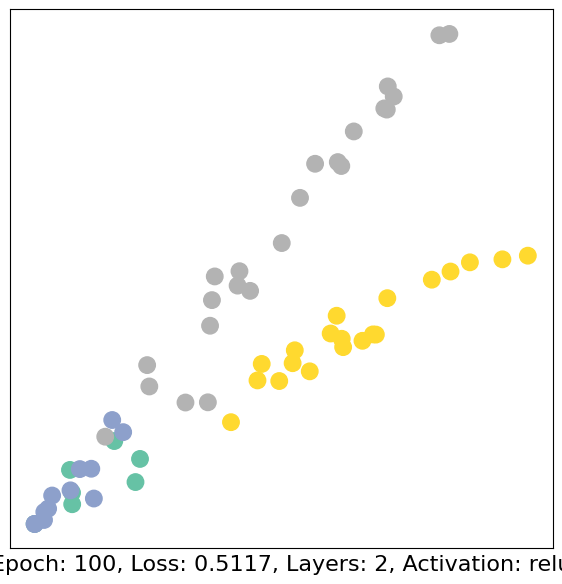

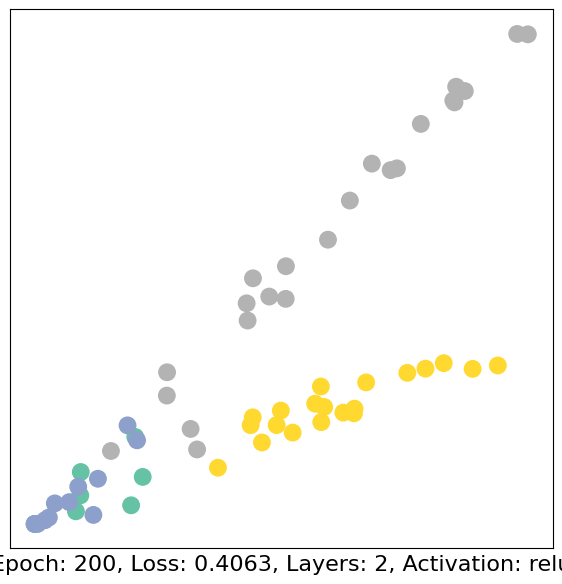

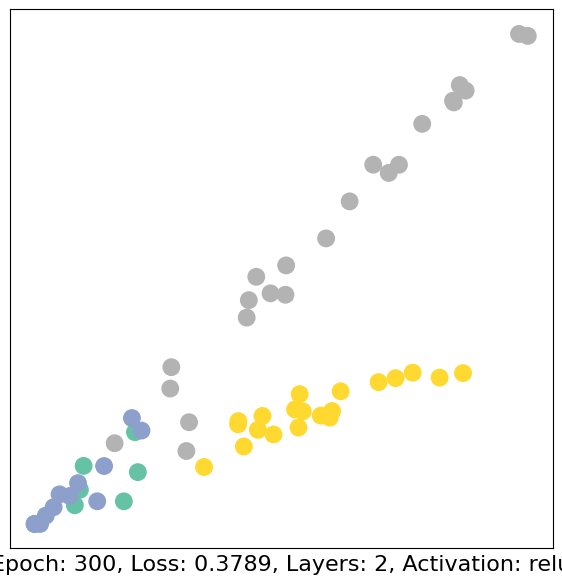

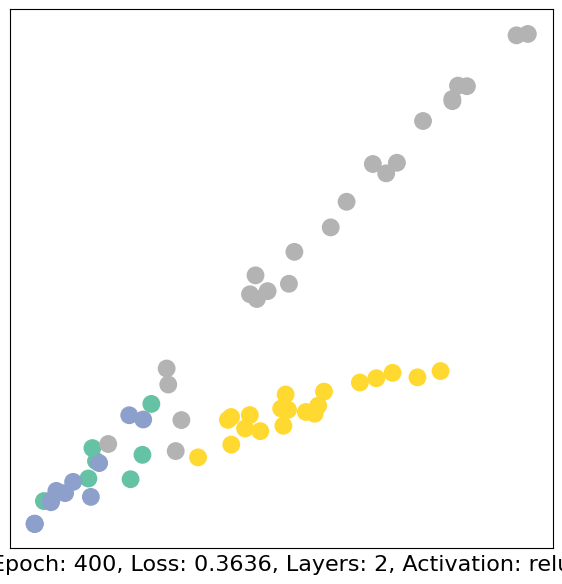

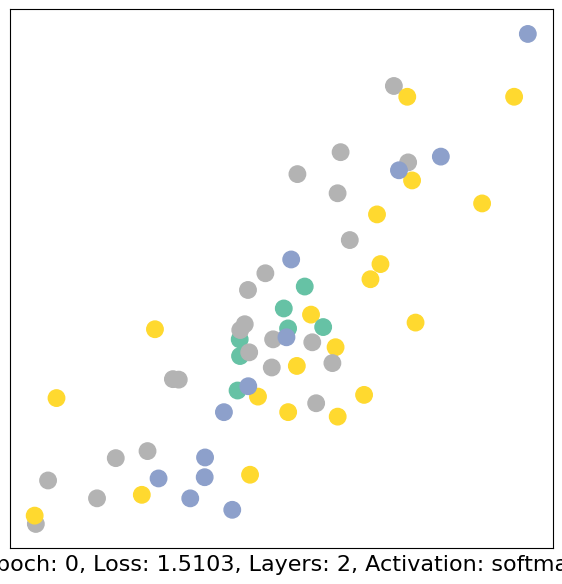

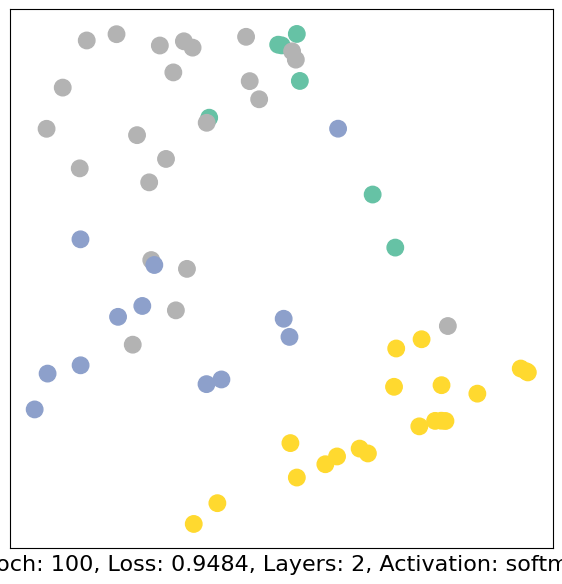

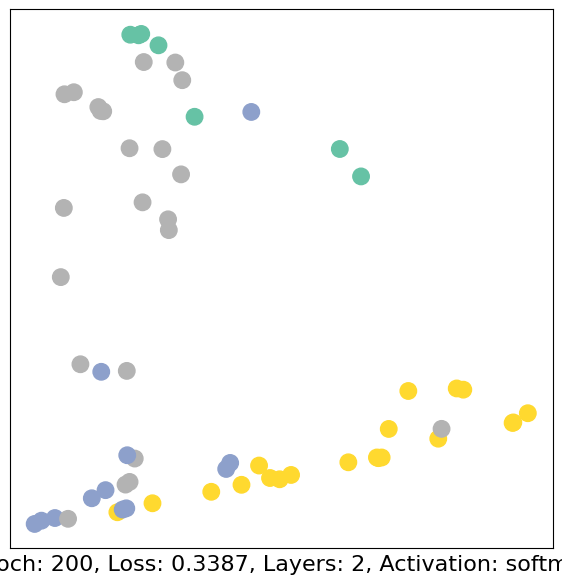

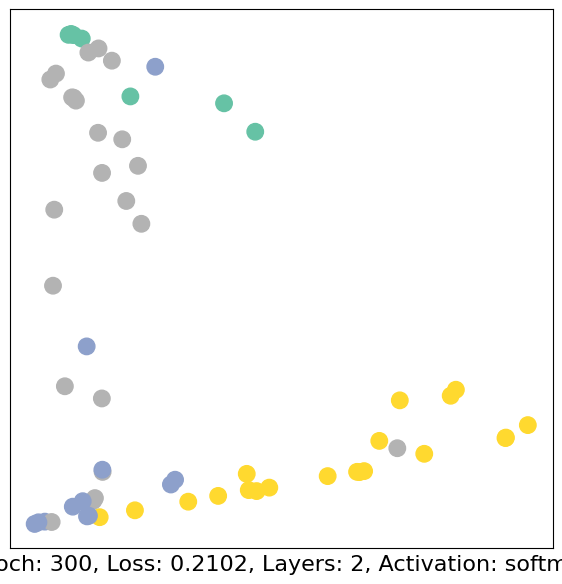

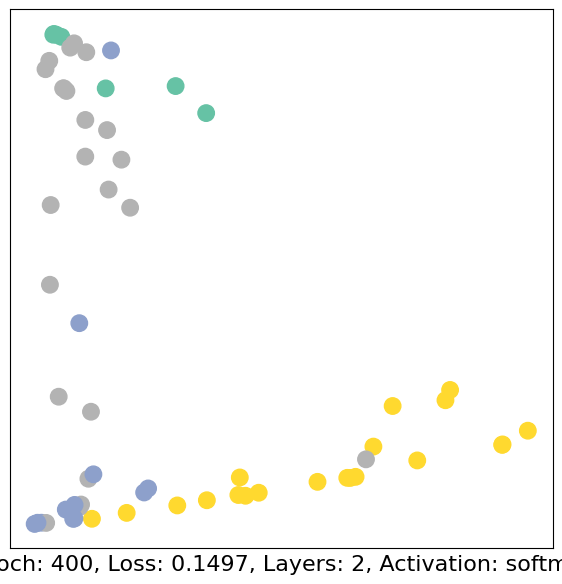

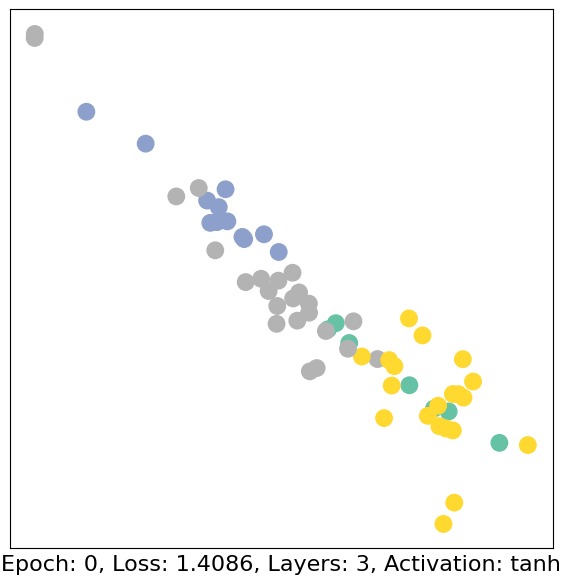

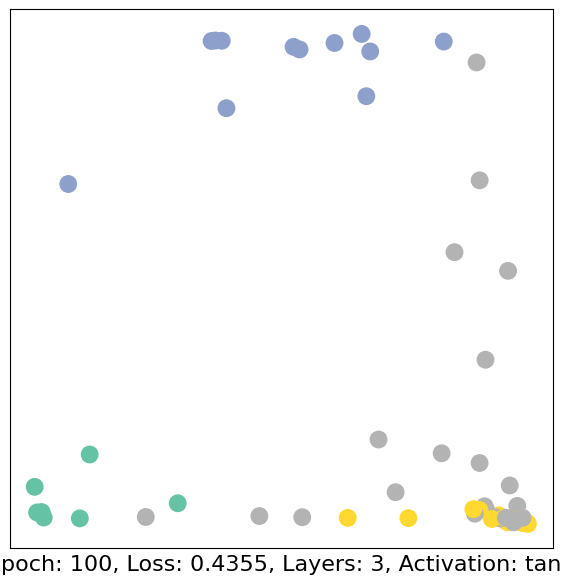

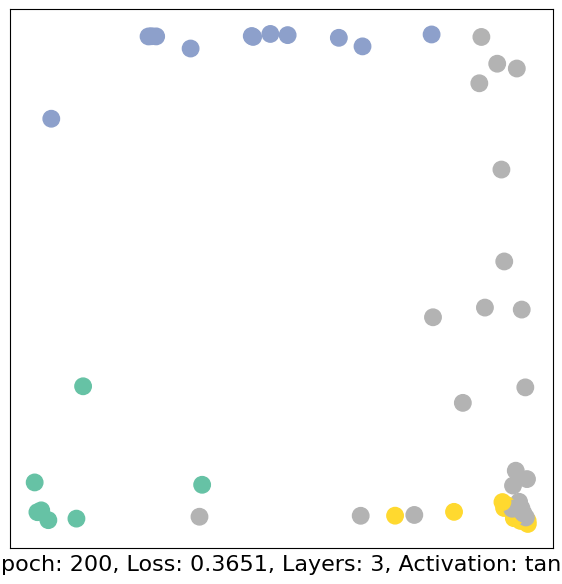

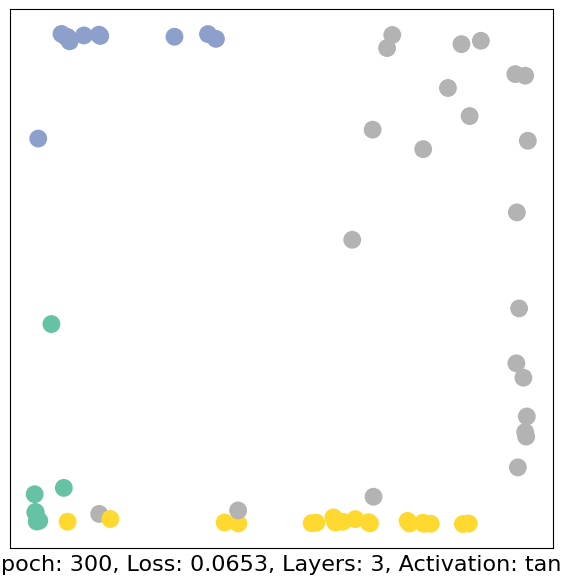

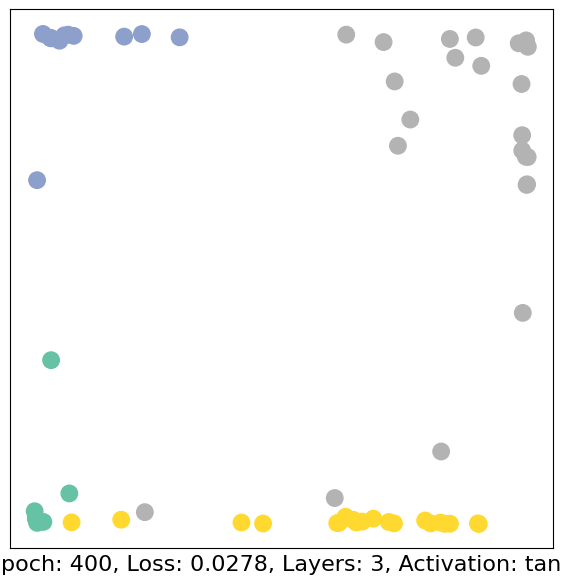

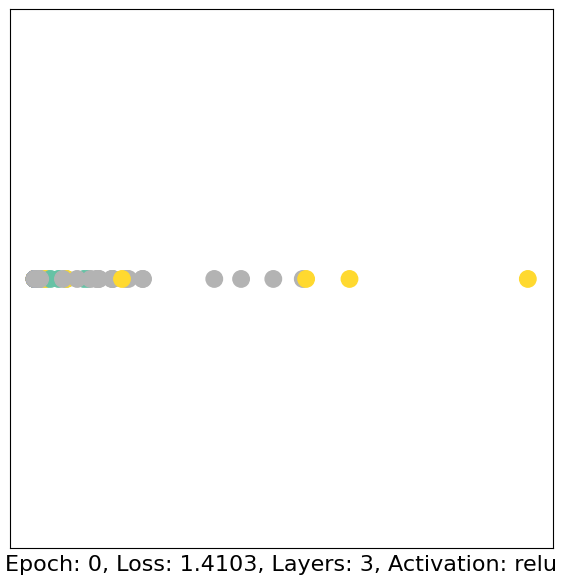

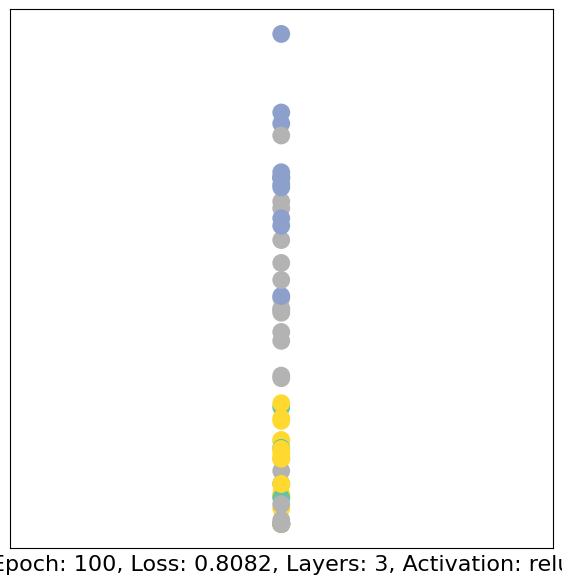

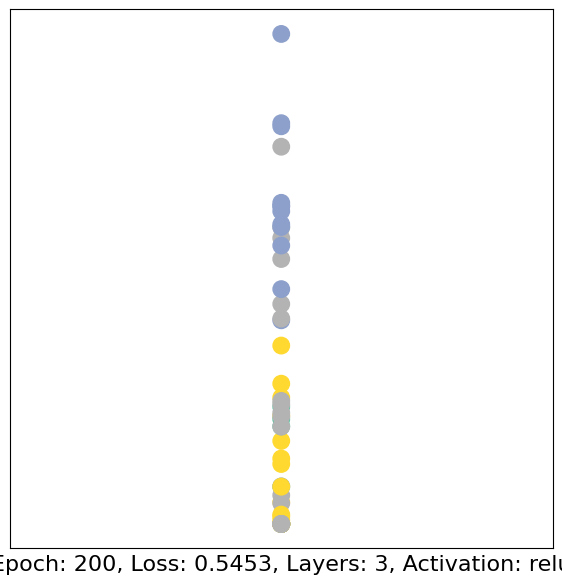

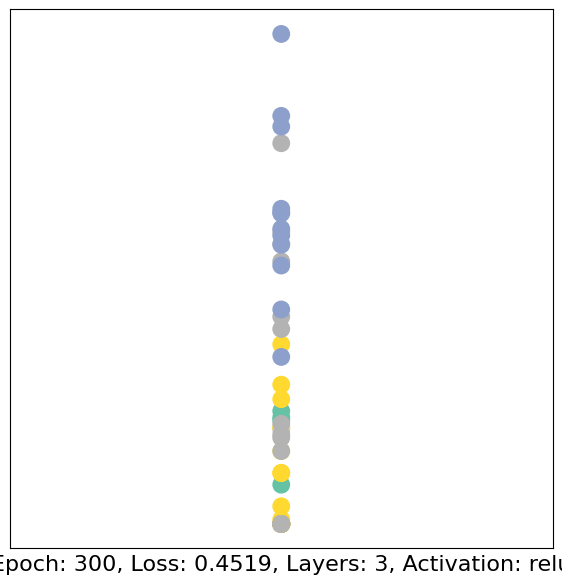

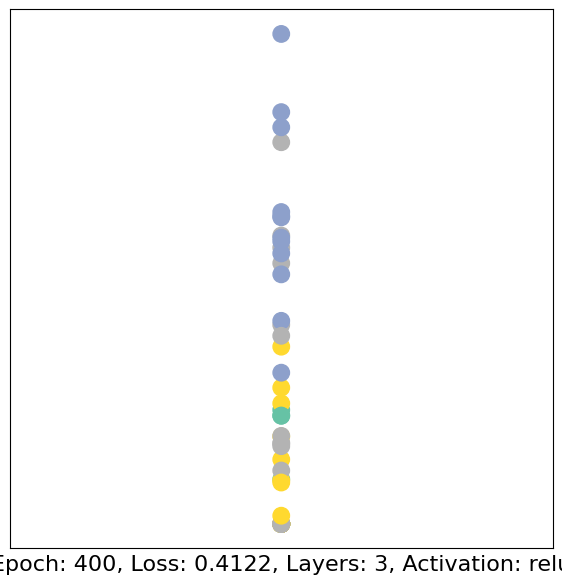

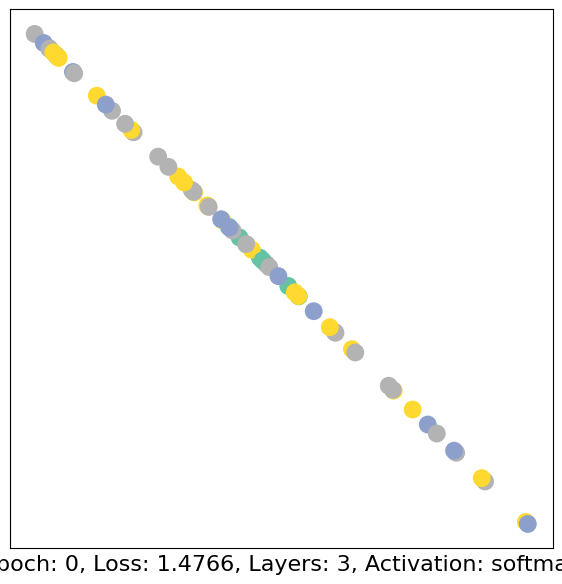

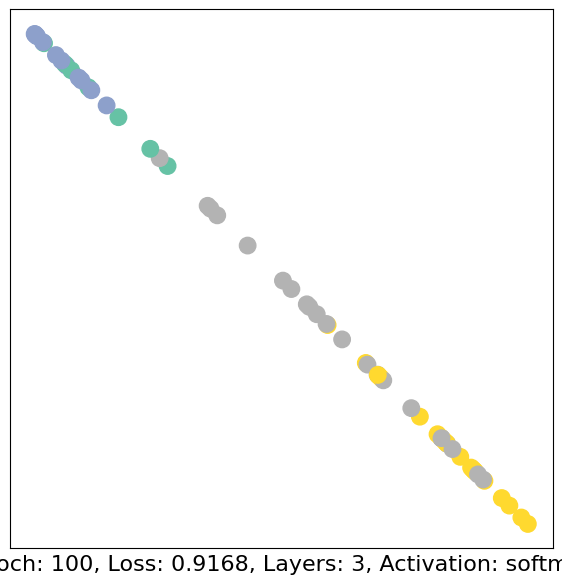

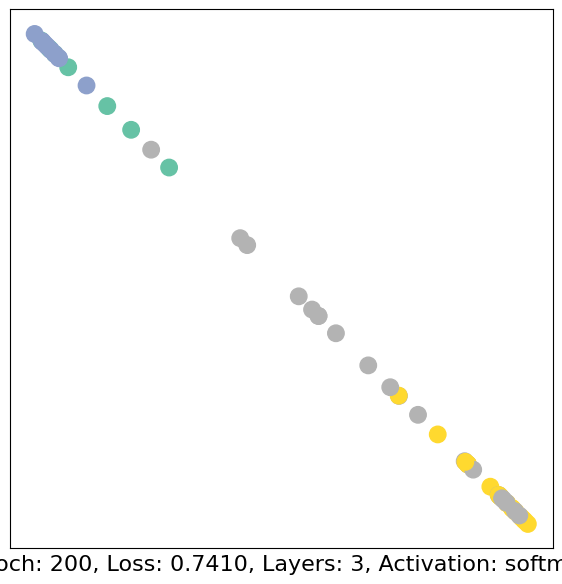

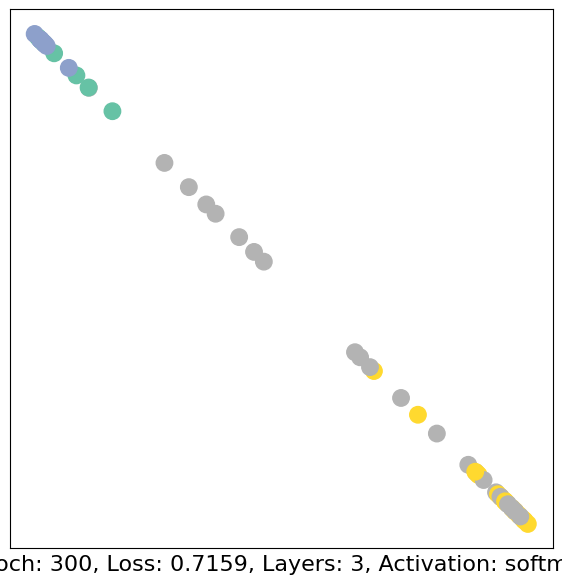

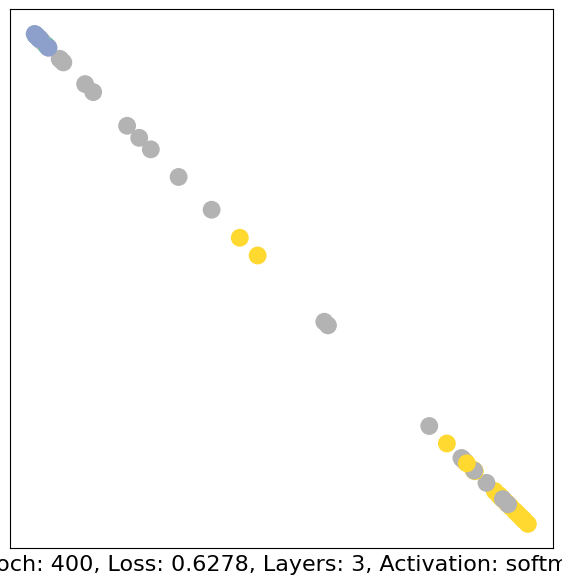

In [ ]:
results = []
for num_layers in [1, 2, 3]:
    for activation in ['tanh', 'relu', 'softmax']:
        model = GCN(num_layers=num_layers, activation=activation)
        optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
        criterion = torch.nn.CrossEntropyLoss()

        for epoch in range(401):
            loss, h = train(data)
            if epoch % 100 == 0:
                visualize_embedding(h, color=data.y, epoch=epoch, loss=loss, num_layers=num_layers, activation=activation)

        out, _ = model(data.x, data.edge_index)
        pred = out.argmax(dim=1)
        test_mask = torch.logical_not(data.train_mask)
        test_correct = pred[test_mask] == data.y[test_mask]
        test_acc = int(test_correct.sum()) / int(test_mask.sum())

        results.append((num_layers, activation, test_acc))

In [ ]:
best_result = max(results, key=lambda x: x[2])
print(f'Наилучший результат: {best_result[2]:.4f}, к-во слоев: {best_result[0]}, ф-ция активации: {best_result[1]})')

Наилучший результат: 0.9310, к-во слоев: 2, ф-ция активации: tanh)


In [ ]:
res = []
for num_layers in [1, 2, 3]:
    for activation in ['tanh', 'relu', 'softmax']:
        model = GCN(num_layers=num_layers, activation=activation)
        optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
        criterion = torch.nn.CrossEntropyLoss()

        for epoch in range(401):
            loss, h = train(data)
        out, _ = model(data.x, data.edge_index)
        pred = out.argmax(dim=1)
        test_mask = torch.logical_not(data.train_mask)
        test_correct = pred[test_mask] == data.y[test_mask]
        test_acc = int(test_correct.sum()) / int(test_mask.sum())

        res.append((num_layers, activation, test_acc))

In [ ]:

best_result = max(res, key=lambda x: x[2])
print(f'Наилучший результат: {best_result[2]:.4f}, к-во слоев: {best_result[0]}, ф-ция активации: {best_result[1]})')

Наилучший результат: 0.9310, к-во слоев: 2, ф-ция активации: tanh)
